# MERGE — revisão técnica do notebook

Versão corrigida estruturalmente, sem resultados fabricados. Ler as limitações e tarefas pendentes antes da entrega. O teste oficial permanece reservado à secção 14.

## Estado desta revisão

Correções automáticas realizadas em 3 de novembro de 2026. Sintaxe verificada; execução integral não realizada sem o dataset. Não apresentar esta versão como integralmente conforme. A experiência 9, a demonstração 13.4, a análise manual e a integração na aplicação-base continuam pendentes. Os outputs devem ser produzidos pelo grupo no ambiente real.

In [1]:
from pathlib import Path
from IPython.display import display #biblioteca para exibir objetos no Jupyter Notebook
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path.cwd() / "dataset" / "build" / "MERGE_ECAC" / "merge_ecac"
media_dir = Path.cwd() / "dataset"
metadata = pd.read_csv(data_dir / "metadata.csv")
av_values = pd.read_csv(data_dir / "av_values.csv")
test_ids = set(pd.read_csv(data_dir / "test_songs.csv")["Audio_Song"])
if not test_ids.issubset(set(metadata["Audio_Song"])):
    raise ValueError("Há músicas de teste ausentes de metadata.csv.")

test_mask = metadata["Audio_Song"].isin(test_ids) # Cria uma máscara para identificar as linhas que correspondem às músicas de teste
development = metadata.loc[~test_mask].copy().reset_index(drop=True) # isto server para separar o conjunto de desenvolvimento do conjunto de teste
test = metadata.loc[test_mask].copy().reset_index(drop=True) # tem a função de separar o conjunto de teste do conjunto de desenvolvimento

print(f"Metadata: {len(metadata)} linhas | desenvolvimento: {len(development)} | teste: {test['Audio_Song'].nunique()} músicas únicas") #imprime o número de linhas do metadata, desenvolvimento e teste
print("Quadrantes no desenvolvimento:")
display(development["Quadrant"].value_counts().sort_index().to_frame("número de linhas"))

Metadata: 1348 linhas | desenvolvimento: 932 | teste: 409 músicas únicas
Quadrantes no desenvolvimento:


,número de linhas
Quadrant,
Q1,374
Q2,112
Q3,356
Q4,90


**Interpretação:** separámos primeiro as músicas de teste. As restantes contagens usam apenas o conjunto de desenvolvimento, mantendo no mesmo conjunto as linhas repetidas de cada música.

## 2. Compreensão dos dados

### 2.1 Colunas

A tabela resume o tipo, os valores em falta e os valores distintos de cada coluna. As descrições seguem o dicionário de dados.

In [2]:
meaning = {
    "Audio_Song": "ID do áudio", "Lyric_Song": "ID da letra", "Quadrant": "alvo",
    "AllMusic Id": "ID todasmusicas", "AllMusic Extraction Date": "data da extracao todas",
    "Artist": "artista", "Title": "título", "Relevance": "relevância todasmusicas",
    "Year": "ano", "LowestYear": "data mais antiga", "Duration": "duração (s)",
    "Moods": "etiquetas de humor", "MoodsAll": "etiquetas de humor completas",
    "MoodsAllWeights": "pesos de MoodsAll", "Genres": "géneros", "GenreWeights": "pesos de Genres",
    "Themes": "temas", "ThemeWeights": "pesos de Themes", "Styles": "estilos",
    "StyleWeights": "pesos de Styles", "AppearancesTrackIDs": "IDs de outras edições",
    "AppearancesAlbumIDs": "IDs dos álbuns", "Sample": "amostra de música",
    "SampleURL": "endereço da amostra", "ActualYear": "ano usado pelos autores",
    "num_Genres": "número de géneros", "num_MoodsAll": "número de etiquetas de humor",
}

summary = pd.DataFrame({
    "significado": pd.Series(meaning),
    "tipo": development.dtypes.astype(str),
    "em falta (%)": (development.isna().mean() * 100).round(1),
    "distintos": development.nunique(),
})
display(summary)

,significado,tipo,em falta (%),distintos
Audio_Song,ID do áudio,str,0.0,914
Lyric_Song,ID da letra,str,0.0,914
Quadrant,alvo,str,0.0,4
AllMusic Id,ID todasmusicas,str,0.0,911
AllMusic Extraction Date,data da extracao todas,str,0.0,2
Artist,artista,str,0.0,655
Title,título,str,0.0,898
Relevance,relevância todasmusicas,float64,17.2,757
Year,ano,str,12.4,487
LowestYear,data mais antiga,str,34.5,371


**Interpretação:** os IDs ligam os registos e `Quadrant` é a classe que queremos prever. As etiquetas e os respetivos pesos descrevem cada música; as datas de recolha e a disponibilidade de amostras são informação administrativa.

### 2.2 Cruzamento das fontes

O ficheiro `av_values.csv` contém `Arousal` e `Valence` e é ligado à tabela principal pelos IDs da música. O dicionário indica que cada música deve ter áudio e letra; as capas são opcionais. Como as pastas estão organizadas por quadrante, o caminho dos ficheiros revela a classe.

In [3]:
keys = ["Audio_Song", "Lyric_Song"]
joined = development.merge(av_values, on=keys, how="left", validate="many_to_one", indicator=True)
print(f"Pares únicos em metadata: {development[keys].drop_duplicates().shape[0]}")
print(f"Pares encontrados em av_values: {joined[keys + ['Arousal', 'Valence']].drop_duplicates().shape[0]}")
print(f"Linhas repetidas em metadata: {development.duplicated(keys).sum()}")
print(f"Linhas sem correspondência em av_values: {(joined['_merge'] != 'both').sum()}")

media = []
for label, folder, column, extension in [
    ("áudio", "audio", "Audio_Song", ".mp3"),
    ("letras", "lyrics", "Lyric_Song", ".txt"),
    ("capas", "album_covers", "Audio_Song", ".jpg"),
]:
    paths = [p for p in (media_dir / folder).rglob(f"*{extension}") if p.is_file() and not p.name.startswith("._")]
    file_quadrant = {p.stem: p.parent.name for p in paths}
    songs = development[[column, "Quadrant"]].drop_duplicates()
    present = songs[column].isin(file_quadrant)
    wrong = sum(file_quadrant.get(row[column]) != row["Quadrant"] for _, row in songs.loc[present].iterrows())
    media.append({"Fonte": label, "Presente": int(present.sum()), "Faltando": int((~present).sum()), "pasta com quadrante errado": wrong})
display(pd.DataFrame(media))

Pares únicos em metadata: 914
Pares encontrados em av_values: 914
Linhas repetidas em metadata: 18
Linhas sem correspondência em av_values: 0


,Fonte,Presente,Faltando,pasta com quadrante errado
0,áudio,914,0,0
1,letras,914,0,0
2,capas,825,89,0


**Interpretação:** há linhas repetidas na tabela principal, por isso várias linhas podem corresponder à mesma música em `av_values`. O áudio e as letras existem para todas as músicas analisadas; faltam algumas capas. Os ficheiros encontrados estão na pasta do quadrante indicado, mas não devemos usar essa pasta como preditor, porque ela revela a resposta.

### 2.3 Variáveis que podem revelar a resposta

- `Quadrant` é a classe que queremos prever, por isso não pode ser usado como variável de entrada.
- `Arousal` e `Valence` definem o quadrante através do limite 0,5 e também revelam diretamente a resposta.
- As pastas de áudio, letras e capas estão organizadas por quadrante; os respetivos caminhos também revelam a classe.

Os IDs identificam músicas e ficheiros. A documentação não indica que o seu conteúdo codifique o quadrante.

## 3. Análise exploratória

### 3.1–3.2 Distribuições, valores em falta e valores suspeitos

In [4]:
missing = development.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("Ausências por coluna (%):")
display(missing.to_frame("em falta (%)"))
print("Colunas quase vazias (>= 90%):", missing[missing >= 90].index.tolist())
constant = [c for c in development if development[c].nunique(dropna=True) <= 1]
print("Colunas constantes:", constant if constant else "nenhuma")

for column in ["Relevance", "Duration", "Sample", "ActualYear", "num_Genres", "num_MoodsAll"]:
    values = pd.to_numeric(development[column], errors="coerce") #isto faz a conversão da coluna para valores numéricos, ignorando erros
    print(f"{column}: mín. {values.min():g}, mediana {values.median():g}, máx. {values.max():g}") #o calculo da mediana é feito com o método median() do pandas, que retorna o valor central de uma série de dados

for column in ["Year", "LowestYear"]:
    print(f"\nValores mais frequentes em {column}:")
    display(development[column].value_counts(dropna=False).head(5).to_frame("frequência"))

Ausências por coluna (%):


,em falta (%)
num_MoodsAll,98.9
num_Genres,98.9
LowestYear,34.5
ActualYear,22.7
Duration,20.4
Relevance,17.2
ThemeWeights,16.2
Themes,16.2
Genres,13.5
Year,12.4


Colunas quase vazias (>= 90%): ['num_MoodsAll', 'num_Genres']
Colunas constantes: nenhuma
Relevance: mín. 1.01027, mediana 1.03932, máx. 1.84
Duration: mín. -1, mediana 197, máx. 367000
Sample: mín. 0, mediana 1, máx. 1
ActualYear: mín. 0, mediana 1997, máx. 9999
num_Genres: mín. 0, mediana 1, máx. 2
num_MoodsAll: mín. 0, mediana 12.5, máx. 23

Valores mais frequentes em Year:


,frequência
Year,
NaN,116
1983-??-??,10
1997-??-??,8
1958-??-??,8
1989-??-??,8



Valores mais frequentes em LowestYear:


,frequência
LowestYear,
NaN,322
1994-??-??,8
1993-??-??,7
1986-??-??,7
1983-??-??,7


**Interpretação:** `Duration` tem valores negativos, apesar de o dicionário indicar que a duração deve ser positiva. Também surgem durações e anos extremos que convém verificar na etapa de limpeza. As colunas quase vazias fornecem pouca informação nesta análise. Por agora, apenas identificamos estes casos: não alteramos os dados.

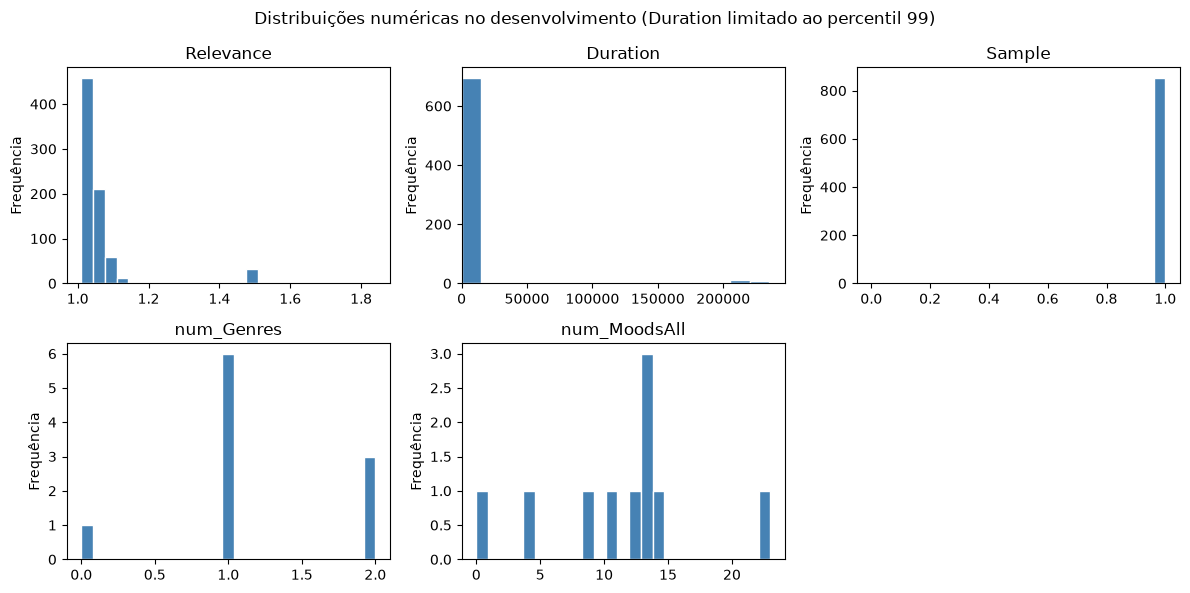

In [5]:
numeric = development.select_dtypes(include="number").columns.tolist()
fig, axes = plt.subplots(max(1, (len(numeric) + 2) // 3), 3, figsize=(12, 3 * max(1, (len(numeric) + 2) // 3)), squeeze=False)
for ax, column in zip(axes.flat, numeric):
    values = development[column].dropna()
    ax.hist(values, bins=25, color="steelblue", edgecolor="white")
    ax.set(title=column, ylabel="Frequência")
    if column == "Duration" and len(values):
        ax.set_xlim(min(0, values.min()), values.quantile(0.99))
for ax in axes.flat[len(numeric):]:
    ax.set_visible(False)
fig.suptitle("Distribuições numéricas no desenvolvimento (Duration limitado ao percentil 99)")
fig.tight_layout()
plt.show()

**Interpretação:** os histogramas mostram como se distribuem os valores numéricos. No gráfico de `Duration`, o eixo está limitado ao percentil 99 para facilitar a leitura; os valores acima desse limite continuam nos dados e serão investigados.

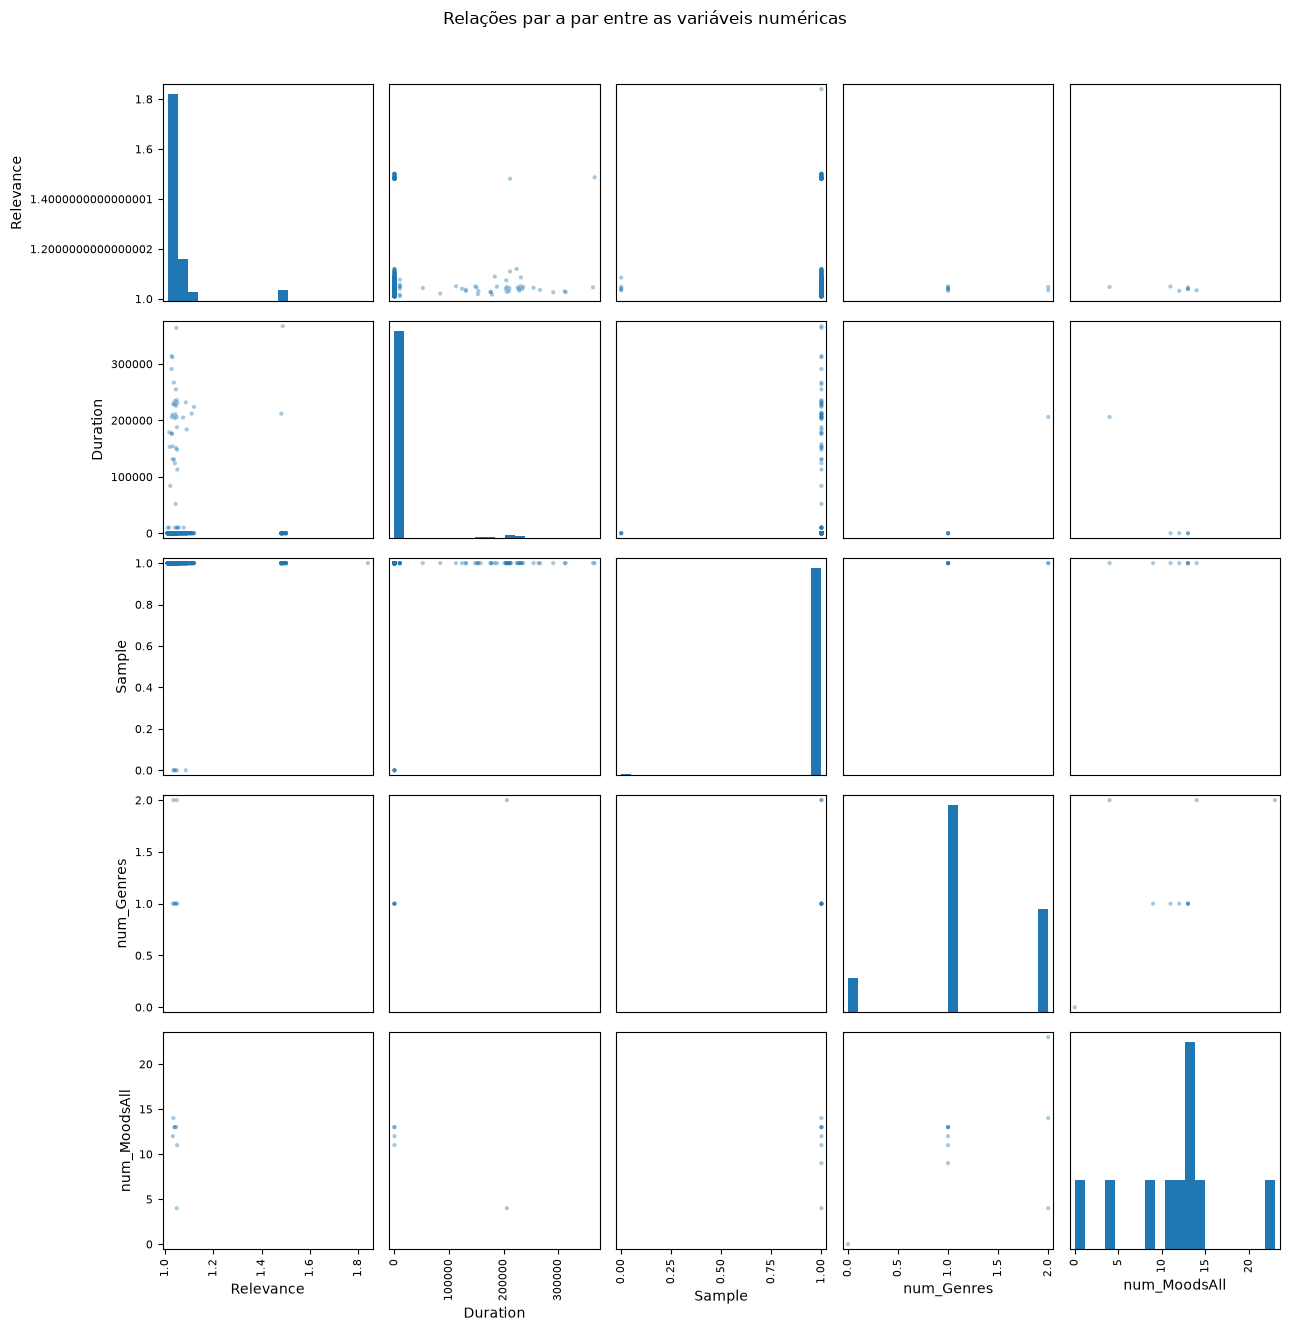

In [6]:
numeric = development.select_dtypes(include="number").columns.tolist()
fig = pd.plotting.scatter_matrix(
    development[numeric],
    figsize=(13, 13),
    diagonal="hist",
    alpha=0.4,
    marker=".",
    hist_kwds={"bins": 20},
)
plt.suptitle("Relações par a par entre as variáveis numéricas", y=1.02)
plt.tight_layout()
plt.show()

**Interpretação:** cada painel compara duas variáveis numéricas e a diagonal mostra a distribuição de cada uma. Os valores em falta não foram preenchidos. As colunas quase vazias e os valores extremos dificultam a leitura, por isso estas relações devem ser vistas como uma primeira exploração.

### 3.3–3.4 Relação entre cada coluna e o quadrante

Para comparar as colunas, dividimos o conjunto de desenvolvimento em cinco partes e, em cada ronda, prevemos a classe mais frequente para cada valor (ou intervalo numérico). Usamos macro-F1, que dá o mesmo peso às quatro classes, e comparamos o resultado com uma previsão de referência baseada na classe mais frequente. As linhas da mesma música ficam sempre na mesma parte. É uma comparação inicial de cada coluna, não substitui o modelo k-NN do projeto.

In [7]:
classes = ["Q1", "Q2", "Q3", "Q4"]
songs = development[["Audio_Song", "Quadrant"]].drop_duplicates()
rng = np.random.default_rng(42)
fold_map = {}
for label in classes:
    ids = songs.loc[songs["Quadrant"] == label, "Audio_Song"].to_numpy().copy()
    rng.shuffle(ids)
    fold_map.update({song: i % 5 for i, song in enumerate(ids)})
fold = development["Audio_Song"].map(fold_map)

def keys_for(train, valid):
    x_train = pd.to_numeric(train, errors="coerce")
    x_valid = pd.to_numeric(valid, errors="coerce")
    if train.notna().sum() and x_train.notna().sum() / train.notna().sum() >= 0.95:
        edges = np.r_[-np.inf, x_train.dropna().quantile([.2, .4, .6, .8]).unique(), np.inf]
        a = pd.cut(x_train, edges, include_lowest=True).astype(str).where(x_train.notna(), "[em falta]")
        b = pd.cut(x_valid, edges, include_lowest=True).astype(str).where(x_valid.notna(), "[em falta]")
    else:
        a, b = train.fillna("[em falta]").astype(str), valid.fillna("[em falta]").astype(str)
    return a, b

def macro_f1(actual, predicted):
    values = []
    for label in classes:
        tp = ((actual == label) & (predicted == label)).sum()
        fp = ((actual != label) & (predicted == label)).sum()
        fn = ((actual == label) & (predicted != label)).sum()
        values.append(2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0)
    return np.mean(values)

features = joined.drop(columns=["Quadrant", "_merge"]).columns
results = []
for feature in features:
    prediction = pd.Series(index=joined.index, dtype="object")
    baseline = pd.Series(index=joined.index, dtype="object")
    for part in range(5):
        valid = fold == part
        train = ~valid
        train_key, valid_key = keys_for(joined.loc[train, feature], joined.loc[valid, feature])
        labels = joined.loc[train, "Quadrant"]
        majority = labels.value_counts().idxmax()
        lookup = pd.DataFrame({"key": train_key, "label": labels}).groupby("key")["label"].agg(lambda x: x.value_counts().idxmax())
        prediction.loc[valid] = valid_key.map(lookup).fillna(majority)
        baseline.loc[valid] = majority
    actual = joined["Quadrant"]
    results.append({
        "coluna": feature,
        "accuracy": (prediction == actual).mean(),
        "macro-F1": macro_f1(actual, prediction),
        "macro-F1 referência": macro_f1(actual, baseline),
    })

results = pd.DataFrame(results).sort_values("macro-F1", ascending=False).reset_index(drop=True)
display(results.round(3))
suspects = results[results["coluna"].isin(["Arousal", "Valence"])]
reference = results["macro-F1 referência"].mean()
print(f"Suspeitas Arousal/Valence acima da referência: {(suspects['macro-F1'] > reference).sum()} de {len(suspects)}.")

,coluna,accuracy,macro-F1,macro-F1 referência
0,Genres,0.591,0.497,0.143
1,Styles,0.578,0.495,0.143
2,Arousal,0.721,0.494,0.143
3,Artist,0.535,0.447,0.143
4,Valence,0.723,0.407,0.143
5,Moods,0.533,0.396,0.143
6,Themes,0.541,0.388,0.143
7,Year,0.484,0.381,0.143
8,MoodsAll,0.488,0.337,0.143
9,StyleWeights,0.464,0.336,0.143


Suspeitas Arousal/Valence acima da referência: 2 de 2.


**Interpretação:** as colunas no topo têm maior associação com o quadrante nesta comparação. `Arousal` e `Valence` não devem entrar no modelo, porque são usadas para definir a própria classe. Nas outras colunas, uma associação elevada não prova, por si só, fuga de informação nem uma relação de causa.

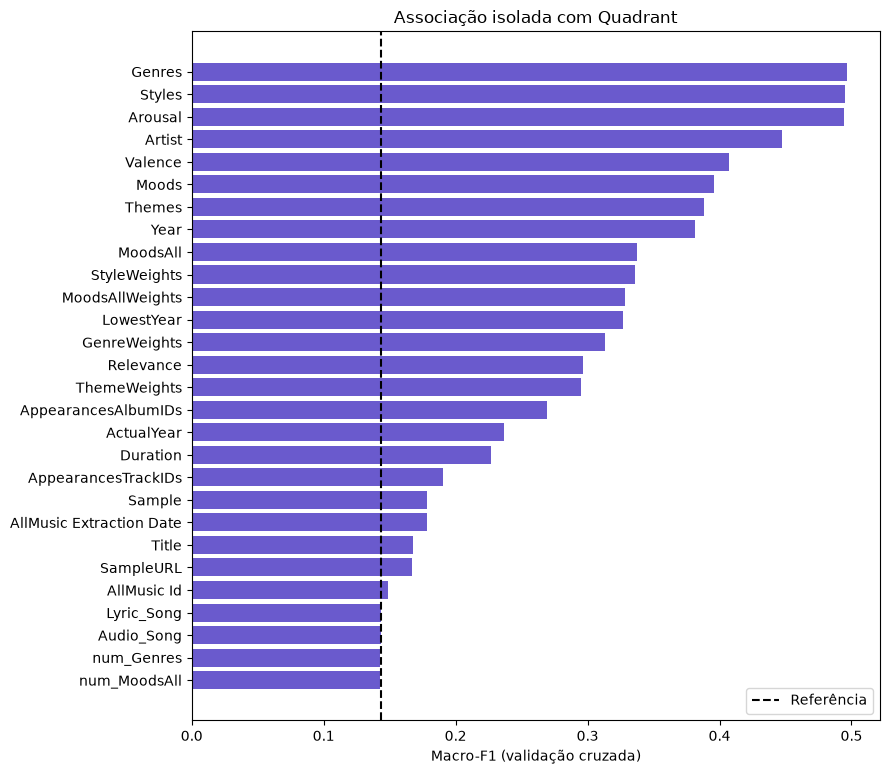

In [8]:
plot = results.sort_values("macro-F1")
fig, ax = plt.subplots(figsize=(9, max(6, len(plot) * 0.28)))
ax.barh(plot["coluna"], plot["macro-F1"], color="slateblue")
ax.axvline(reference, color="black", linestyle="--", label="Referência")
ax.set(xlabel="Macro-F1 (validação cruzada)", title="Associação isolada com Quadrant")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretação:** o gráfico ordena as colunas pela pontuação macro-F1 e mostra a linha de referência. Os valores exatos estão na tabela anterior. As variáveis que podem revelar a resposta foram identificadas antes desta comparação.

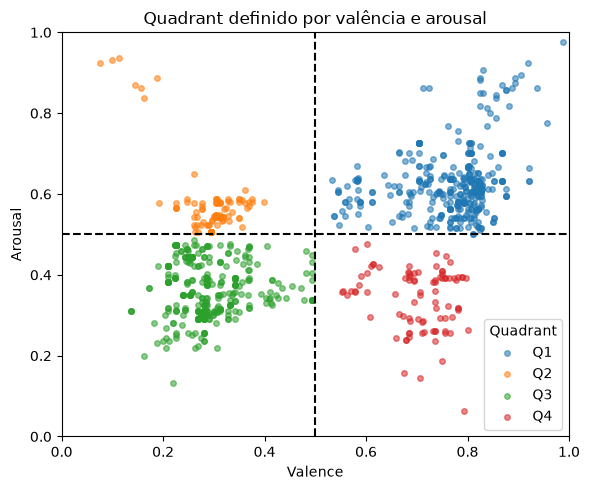

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, group in joined.groupby("Quadrant"):
    ax.scatter(group["Valence"], group["Arousal"], s=16, alpha=.55, label=label)
ax.axvline(.5, color="black", linestyle="--")
ax.axhline(.5, color="black", linestyle="--")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Valence", ylabel="Arousal", title="Quadrant definido por valência e arousal")
ax.legend(title="Quadrant")
fig.tight_layout()
plt.show()

**Interpretação:** as linhas tracejadas mostram os limites de 0,5 usados para formar os quadrantes. Como `Valence` e `Arousal` determinam a classe, não devem ser usadas para a prever.

### 3.5 Artistas que aparecem no desenvolvimento e no teste

In [10]:
development_artists = set(development["Artist"].dropna())
test_songs = test.drop_duplicates("Audio_Song")
shared = test_songs["Artist"].isin(development_artists)
print(f"Músicas de teste com artista (mesma grafia) no desenvolvimento: {shared.sum()} de {len(test_songs)}.")
print(f"Artistas distintos partilhados: {test_songs.loc[shared, 'Artist'].nunique()}.")
artist_song_counts = development.groupby("Artist")["Audio_Song"].nunique().sort_values(ascending=False)
display(artist_song_counts.rename("músicas por artista").to_frame())


Músicas de teste com artista (mesma grafia) no desenvolvimento: 200 de 409.
Artistas distintos partilhados: 104.


,músicas por artista
Artist,
Billie Holiday,17
The Beatles,8
Jimmy Reed,8
Madonna,7
Elvis Presley,7
...,...
Whitesnake,1
Whitesnake,1
Wilco,1


**Interpretação:** esta contagem compara os nomes dos artistas tal como estão escritos; diferenças de grafia podem esconder correspondências. É uma verificação de possível sobreposição entre desenvolvimento e teste, pedida no enunciado. Não usa os rótulos do teste nem mede o desempenho de um modelo.

## Síntese das perguntas 2 e 3

A análise descreve as colunas, os valores em falta, a cobertura dos ficheiros e a relação inicial entre cada variável e o quadrante. Encontrámos valores a investigar e variáveis que revelam diretamente a classe, pelo que não devem ser usadas como preditores. Nesta parte, os dados ainda não foram alterados.

# 4. Limpeza dos dados

Nesta secção procuramos duplicados, analisamos os valores em falta e identificamos erros e possíveis outliers. Só depois aplicamos regras justificadas. O conjunto de teste continua separado: as regras e estatísticas são definidas no desenvolvimento e aplicadas ao teste sem voltar a ajustá-las.

## 4.1 Duplicados

Comparamos os IDs, artista e título, o conteúdo dos ficheiros de áudio e das letras. Um nome igual é apenas uma pista; ficheiros idênticos dão evidência mais forte de que se trata da mesma gravação.

In [11]:
import hashlib

def media_index(folder: str, suffix: str) -> dict[str, Path]:
    return {p.stem: p for p in (media_dir / folder).rglob(f"*{suffix}") if p.is_file() and not p.name.startswith("._")} #retornando um dicionário com o nome do arquivo (sem extensão) como chave e o caminho completo como valor

def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest() #retorna o hash SHA-256 do conteúdo do arquivo lido como bytes

audio_paths = media_index("audio", ".mp3")
lyric_paths = media_index("lyrics", ".txt")
unique_songs = metadata.drop_duplicates("Audio_Song").copy()
unique_songs["split"] = np.where(unique_songs["Audio_Song"].isin(test_ids), "teste", "desenvolvimento")
unique_songs["audio_hash"] = unique_songs["Audio_Song"].map(lambda song: sha256(audio_paths[song]) if song in audio_paths else None)
unique_songs["lyric_hash"] = unique_songs["Lyric_Song"].map(lambda song: sha256(lyric_paths[song]) if song in lyric_paths else None)

audio_groups = unique_songs.dropna(subset="audio_hash").groupby("audio_hash")
lyric_groups = unique_songs.dropna(subset="lyric_hash").groupby("lyric_hash")
same_audio = audio_groups.filter(lambda group: group["Audio_Song"].nunique() > 1)
same_lyrics = lyric_groups.filter(lambda group: group["Lyric_Song"].nunique() > 1)
same_track_id = metadata.groupby("AllMusic Id").agg(
    musicas=("Audio_Song", "nunique"), artistas=("Artist", "nunique"), titulos=("Title", "nunique")
).query("musicas > 1 or artistas > 1 or titulos > 1")
cross_split_audio = sum(group["split"].nunique() > 1 for _, group in audio_groups)
artist_variants = metadata.groupby("AllMusic Id")["Artist"].nunique().gt(1).sum()
title_variants = metadata.groupby("AllMusic Id")["Title"].nunique().gt(1).sum()

duplicate_evidence = pd.DataFrame([
    {"evidência": "Linhas exatamente repetidas no desenvolvimento", "grupos/registos": int(development.duplicated().sum())},
    {"evidência": "IDs AllMusic ligados a mais de uma música", "grupos/registos": int((metadata.groupby("AllMusic Id")["Audio_Song"].nunique() > 1).sum())},
    {"evidência": "Gravações de áudio idênticas com IDs diferentes", "grupos/registos": int(same_audio["audio_hash"].nunique())},
    {"evidência": "Letras idênticas com IDs diferentes", "grupos/registos": int(same_lyrics["lyric_hash"].nunique())},
    {"evidência": "IDs AllMusic com grafias diferentes de artista", "grupos/registos": int(artist_variants)},
    {"evidência": "IDs AllMusic com títulos diferentes", "grupos/registos": int(title_variants)},
    {"evidência": "Gravações de áudio idênticas nos dois lados da divisão", "grupos/registos": int(cross_split_audio)},
    ])
display(duplicate_evidence)
display(same_audio[["Audio_Song", "Lyric_Song", "Artist", "Title", "split"]].head(12))

,evidência,grupos/registos
0,Linhas exatamente repetidas no desenvolvimento,18
1,IDs AllMusic ligados a mais de uma música,1
2,Gravações de áudio idênticas com IDs diferentes,2
3,Letras idênticas com IDs diferentes,3
4,IDs AllMusic com grafias diferentes de artista,1
5,IDs AllMusic com títulos diferentes,1
6,Gravações de áudio idênticas nos dois lados da...,1


,Audio_Song,Lyric_Song,Artist,Title,split
165,MT0003503243,MT0003503243,Godsmack,I F****** Hate You,desenvolvimento
220,MT0011933875,MT0011933875,Luther Vandross,Never Too Much,desenvolvimento
931,A114-120,L004-120,Luther Vandross,Never Too Much - Remastered,desenvolvimento
1058,A028,L078,Godsmack,I Fucking Hate You,teste


**Interpretação:** linhas exatamente repetidas podem ser removidas sem perder informação. Um ID AllMusic partilhado ou ficheiros idênticos pedem uma verificação mais cuidada; não juntamos automaticamente gravações diferentes só porque artista e título coincidem. Se a mesma gravação estiver nos dois lados, removê-la do desenvolvimento evita que a validação beneficie de uma cópia presente no teste, sem alterar o teste. Para validação cruzada, as músicas do mesmo artista devem ficar no mesmo grupo.

## 4.2 Valores em falta

A percentagem em falta, por si só, não explica a causa. Comparamos os padrões com o quadrante e com o número de músicas por artista; estas associações são indícios, não provam o mecanismo.

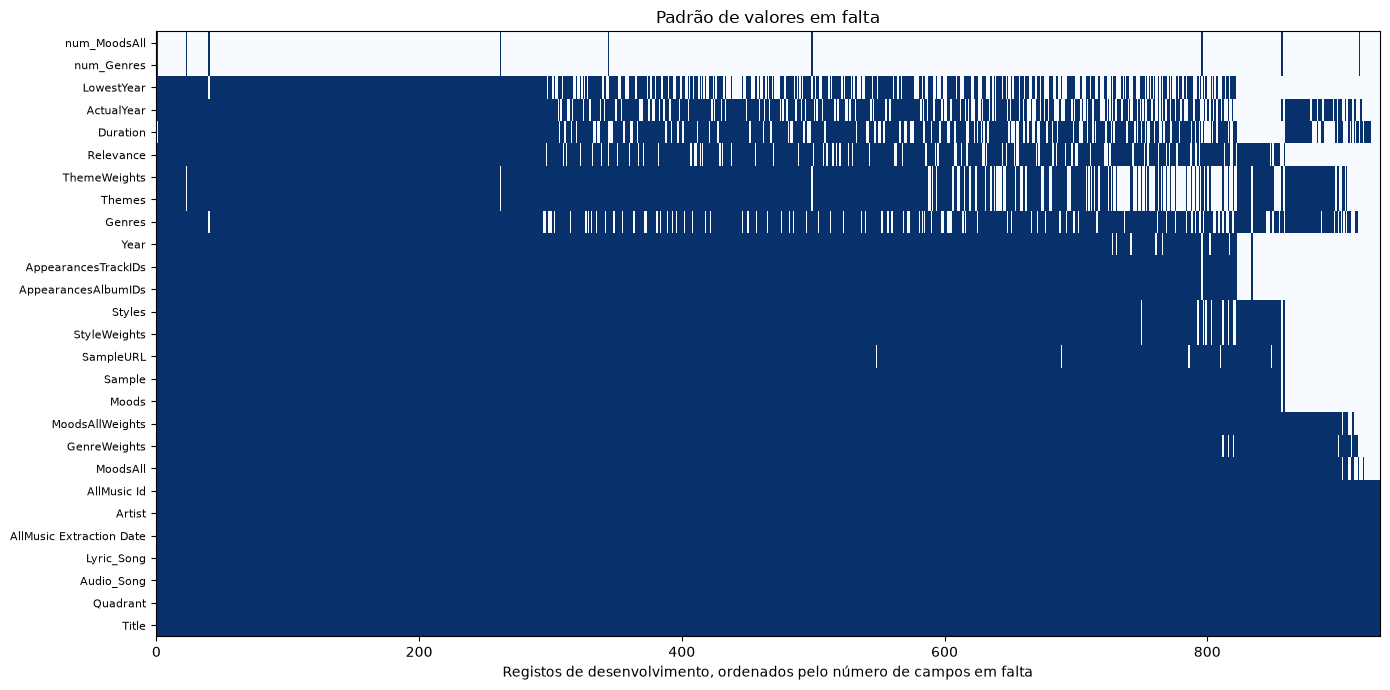

,coluna,em falta (%),Q1 (%),Q2 (%),Q3 (%),Q4 (%),p (quadrante),p (tamanho artista)
26,num_MoodsAll,98.9,97.9,100.0,99.4,100.0,0.0696,0.9393
25,num_Genres,98.9,97.9,100.0,99.4,100.0,0.0696,0.9393
9,LowestYear,34.5,40.6,21.4,31.5,37.8,0.0009,0.2412
24,ActualYear,22.7,22.5,21.4,22.8,25.6,0.9117,0.0241
10,Duration,20.4,19.3,10.7,22.5,28.9,0.0084,0.7176
7,Relevance,17.2,16.8,15.2,18.5,15.6,0.8074,0.5616
17,ThemeWeights,16.2,17.6,32.1,8.7,20.0,0.0000,0.0134
16,Themes,16.2,17.6,32.1,8.7,20.0,0.0000,0.0134
14,Genres,13.5,7.2,9.8,18.5,24.4,0.0000,0.1863
8,Year,12.4,11.5,8.9,13.5,16.7,0.3335,0.7014


In [12]:
from scipy.stats import chi2_contingency

missing_pct = development.isna().mean().mul(100).sort_values(ascending=False)
artist_sizes = development.groupby("Artist")["Audio_Song"].transform("nunique")
artist_size_group = pd.qcut(artist_sizes.rank(method="first"), 4, labels=False)
missing_patterns = development.isna().loc[:, missing_pct.index]
row_order = missing_patterns.sum(axis=1).sort_values(kind="stable").index

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(missing_patterns.loc[row_order].T, aspect="auto", interpolation="nearest", cmap="Blues_r", vmin=0, vmax=1)
ax.set(yticks=np.arange(len(missing_pct)), yticklabels=missing_pct.index, xlabel="Registos de desenvolvimento, ordenados pelo número de campos em falta", title="Padrão de valores em falta")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

missingness_rows: list[dict[str, object]] = []
for column in development.columns:
    column = str(column)
    absent = development[column].isna().astype(int)
    row = {"coluna": column, "em falta (%)": round(100 * absent.mean(), 1)}
    for quadrant in ["Q1", "Q2", "Q3", "Q4"]:
        row[f"{quadrant} (%)"] = round(100 * absent[development["Quadrant"].eq(quadrant)].mean(), 1)
    q_table = pd.crosstab(development["Quadrant"], absent)
    row["p (quadrante)"] = chi2_contingency(q_table)[1] if q_table.shape == (4, 2) else np.nan
    artist_table = pd.crosstab(artist_size_group, absent)
    row["p (tamanho artista)"] = chi2_contingency(artist_table)[1] if artist_table.shape == (4, 2) else np.nan
    missingness_rows.append(row)
missingness_summary = pd.DataFrame.from_records(missingness_rows).sort_values("em falta (%)", ascending=False)
display(missingness_summary.round(4))

**Interpretação:** o mapa mostra se os valores em falta aparecem isolados ou em blocos. As percentagens por quadrante e os testes indicam se a ausência está associada a informação observada. Um valor-p baixo sugere associação, mas não identifica sozinho a causa; a ausência dependente do próprio valor em falta não pode ser confirmada apenas com estes dados.

### 4.2.3 Comparação de imputações

Usamos `Relevance` para comparar métodos num valor observado e depois ocultado aleatoriamente. É uma verificação controlada, não garante o mesmo resultado para colunas cuja ausência não seja aleatória.

In [13]:
imputation_data = development.drop_duplicates("Audio_Song")[["Audio_Song", "Artist", "Relevance"]].copy()
imputation_data["Relevance"] = pd.to_numeric(imputation_data["Relevance"], errors="coerce")
observed = imputation_data.dropna(subset="Relevance")
rng = np.random.default_rng(42)
permutation = rng.permutation(len(observed))
holdout = observed.iloc[permutation[:max(1, int(0.2 * len(observed)))]]
training = observed.iloc[permutation[max(1, int(0.2 * len(observed))):]]
global_median = training["Relevance"].median()
artist_medians = training.groupby("Artist")["Relevance"].median()
predictions = {
    "mediana global": pd.Series(global_median, index=holdout.index),
    "média global": pd.Series(training["Relevance"].mean(), index=holdout.index),
    "mediana do artista (fallback global)": holdout["Artist"].map(artist_medians).fillna(global_median),
}
imputation_scores = pd.DataFrame([
    {"método": name, "MAE": (pred - holdout["Relevance"]).abs().mean(), "RMSE": np.sqrt(((pred - holdout["Relevance"]) ** 2).mean()), "viés": (pred - holdout["Relevance"]).mean()}
    for name, pred in predictions.items()
]).sort_values("MAE")
display(imputation_scores.round(4))

,método,MAE,RMSE,viés
0,mediana global,0.0189,0.0547,-0.0074
2,mediana do artista (fallback global),0.0250,0.0713,0.0033
1,média global,0.0354,0.0576,0.0196


**Interpretação:** a tabela compara o erro nos valores que escondemos, sem os usar para calcular as imputações. Como `Duration` pode faltar precisamente nas faixas mais longas, preencher todas as ausências com uma mediana pode subestimar a duração. Além disso, preencher `Genres` com base em `Quadrant` usaria a própria resposta e criaria fuga de informação. Por isso, a limpeza preserva indicadores de ausência e evita esta imputação por classe.

## 4.3 Erros e inconsistências

Procuramos valores impossíveis isoladamente e pares de valores que se contradizem. As regras abaixo usam o dicionário e a coerência entre colunas.

In [14]:
duration_raw = pd.to_numeric(development["Duration"], errors="coerce")
year_raw = pd.to_numeric(development["ActualYear"], errors="coerce")
duration_units = pd.DataFrame([
    {"regra": "Duração não positiva", "registos": int(duration_raw.le(0).sum())},
    {"regra": "Sentinela 9999 em Duration", "registos": int(duration_raw.eq(9999).sum())},
    {"regra": "Duração acima de 10 000 (prováveis milissegundos)", "registos": int(duration_raw.gt(10000).sum())},
    {"regra": "Duração positiva abaixo de 10 (possíveis minutos)", "registos": int(duration_raw.between(0, 10, inclusive="neither").sum())},
    {"regra": "ActualYear igual a zero", "registos": int(year_raw.eq(0).sum())},
    {"regra": "ActualYear no futuro", "registos": int(year_raw.gt(2026).sum())},
    {"regra": "Relevance não positiva (o dicionário exige valor positivo)", "registos": int(pd.to_numeric(development["Relevance"], errors="coerce").le(0).sum())},
])
display(duration_units)

def extract_year(values):
    return pd.to_numeric(values.astype("string").str.extract(r"(\d{4})", expand=False), errors="coerce")

actual_year = pd.to_numeric(development["ActualYear"], errors="coerce")
lowest_year = extract_year(development["LowestYear"])
year_conflicts = development.loc[actual_year.lt(lowest_year), ["Audio_Song", "Artist", "Title", "ActualYear", "LowestYear"]].copy()
display(year_conflicts.head(20))

weight_pairs = [("MoodsAll", "MoodsAllWeights"), ("Genres", "GenreWeights"), ("Themes", "ThemeWeights"), ("Styles", "StyleWeights")]
def count_nonempty_items(value: object) -> int:
    if pd.isna(value):
        return 0
    return sum(bool(item.strip()) for item in str(value).split(","))

weight_checks = []
for tags, weights in weight_pairs:
    tag_count = development[tags].map(count_nonempty_items)
    weight_count = development[weights].map(count_nonempty_items)
    mismatch = tag_count.ne(weight_count) & (tag_count.gt(0) | weight_count.gt(0))
    weight_checks.append({"etiquetas": tags, "pesos": weights, "pares com contagens diferentes": int(mismatch.sum())})
display(pd.DataFrame(weight_checks))

,regra,registos
0,Duração não positiva,82
1,Sentinela 9999 em Duration,7
2,Duração acima de 10 000 (prováveis milissegundos),46
3,Duração positiva abaixo de 10 (possíveis minutos),18
4,ActualYear igual a zero,7
5,ActualYear no futuro,19
6,Relevance não positiva (o dicionário exige val...,0


,Audio_Song,Artist,Title,ActualYear,LowestYear
78,MT0009321428,"Cure, The",This Is a Lie,1976,21/05/1996
91,MT0011950450,Neil Diamond,Hark! The Herald Angels Sing,1978,22/09/1992
112,MT0007438571,Liz Phair,Divorce Song,1987,22/06/1993
115,MT0005740567,Inner Circle,You've Lost That Lovin' Feelin',1988,21/05/2002
122,MT0003362617,GARTH BROOKS,Which One of Them,1979,10/09/1991
126,MT0034410340,John Lee Hooker,No Rollin' Blues,1900,20/02/1996
145,MT0014798420,Bubba Sparxxx,Ain't Life Grand,2000,04/04/2006
155,MT0030289937,Louis Armstrong,Billie's Blues,1987,09/10/2001
185,MT0001542457,AC/DC,Show Down in Flames,1900,18/11/1997
195,MT0016976154,Patsy Cline,Yes' I Understand,1900,25/06/2007


,etiquetas,pesos,pares com contagens diferentes
0,MoodsAll,MoodsAllWeights,11
1,Genres,GenreWeights,112
2,Themes,ThemeWeights,6
3,Styles,StyleWeights,8


**Interpretação:** durações não positivas e o valor `9999` não representam uma duração válida; valores muito grandes podem estar em milissegundos e valores pequenos podem estar em minutos. Um `ActualYear` igual a zero ou posterior ao ano atual é inválido. Quando `ActualYear` antecede `LowestYear`, a contradição envolve as duas colunas. Se o número de pesos não corresponder ao de etiquetas, não é seguro associar cada peso a uma etiqueta.

## 4.4 Outliers

Comparamos três regras univariadas e duas abordagens multivariadas. Um registo assinalado é um caso a investigar, não um erro automático.

,coluna,z-score > 3,MAD modificado > 3.5,regra IQR
0,Duration,7,11,29
1,Relevance,34,71,97
2,ActualYear,10,14,11
3,Sample,5,0,5


,k,inércia,silhouette
0,2,5239.720,0.908
1,3,4155.177,0.397
2,4,3273.609,0.432
3,5,2568.874,0.440
4,6,2059.044,0.440
5,7,1713.635,0.442
6,8,1490.202,0.342


DBSCAN: min_samples=6; eps=1.615 (joelho da curva das distâncias aos 5 vizinhos, excluindo distâncias nulas); ruído=11 registos.


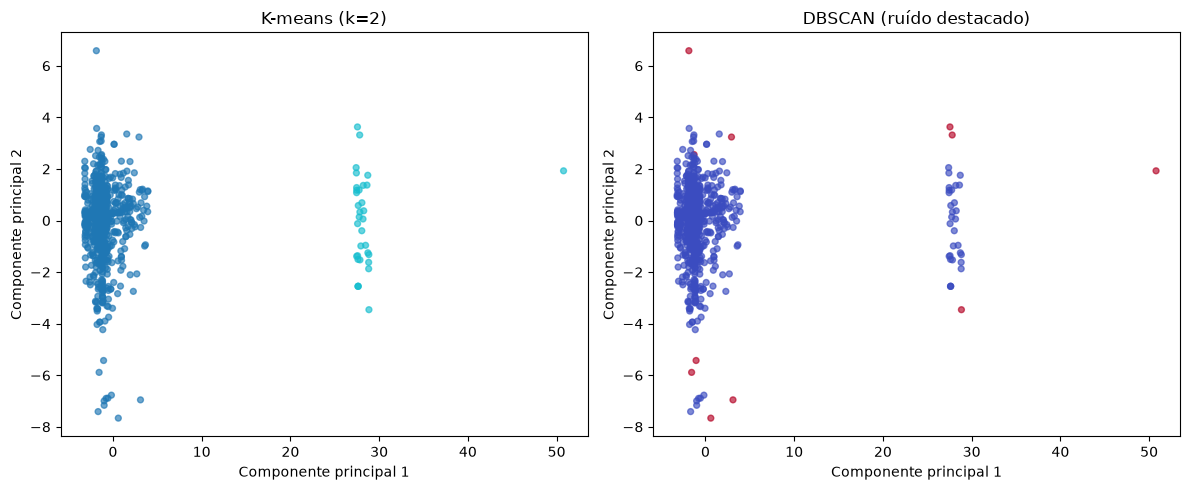

,Audio_Song,Quadrant,Artist,Title,distância ao vizinho mais próximo,DBSCAN ruído
235,MT0004184616,Q3,Ella Fitzgerald,I Gotta Right to Sing the Blues,22.066274,True
770,MT0001435061,Q3,Michael Bloomfield,It's My Own Fault,4.776924,True
694,MT0000848769,Q4,Billie Holiday,Can't Help Lovin' Dat Man,2.762296,True
76,MT0000863543,Q1,Curtis Mayfield,"Love Me, Love Me Now",2.266667,True
927,MT0004131260,Q3,Voivod,Odds & Frauds,2.055638,True
668,MT0000948111,Q1,Elvis Presley,Hot Dog,1.866879,True
383,MT0003536193,Q1,Marvin Gaye,Ain't No Mountain High Enough,1.852665,True
787,A107-115,Q1,David Bowie,Let's Dance,1.819137,True
563,MT0000271454,Q1,Ray Charles,"What'd I Say, Pts. 1 & 2",1.490686,True
723,MT0008813307,Q3,bob dylan,"Oh, Sister",1.398733,False


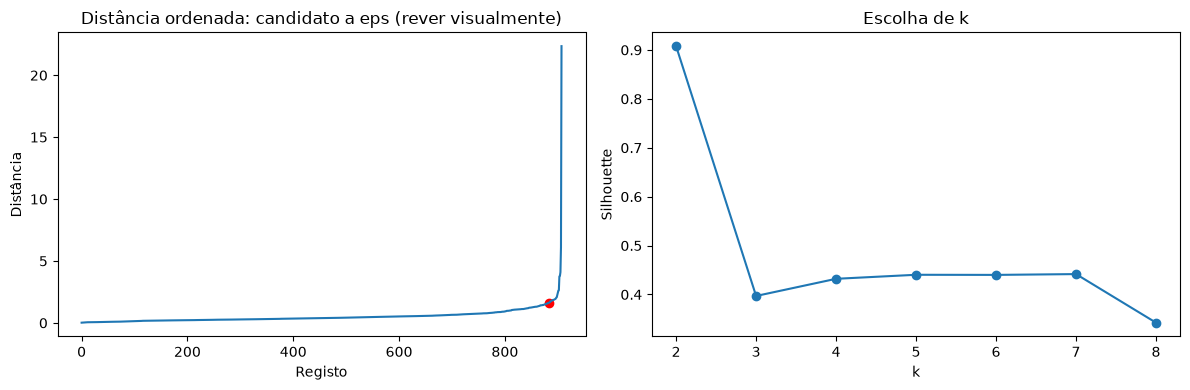

,Audio_Song,Artist,Title
185,MT0001542457,AC/DC,Show Down in Flames
195,MT0016976154,Patsy Cline,Yes' I Understand
235,MT0004184616,Ella Fitzgerald,I Gotta Right to Sing the Blues
383,MT0003536193,Marvin Gaye,Ain't No Mountain High Enough
426,MT0031664726,Christina Milian,Say I
543,A195,Bruno Mars,Dancing with another man
694,MT0000848769,Billie Holiday,Can't Help Lovin' Dat Man
730,MT0003878494,Charlie Poole & the North Carolina Ramblers,Baltimore Fire
770,MT0001435061,Michael Bloomfield,It's My Own Fault
927,MT0004131260,Voivod,Odds & Frauds


In [15]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

numeric_candidates = ["Duration", "Relevance", "ActualYear", "Sample"]
outlier_data = development[numeric_candidates].apply(pd.to_numeric, errors="coerce").copy()
outlier_data.loc[outlier_data["Duration"].le(0) | outlier_data["Duration"].eq(9999), "Duration"] = np.nan
outlier_data.loc[outlier_data["Duration"].gt(10000), "Duration"] /= 1000
minute_values = outlier_data["Duration"].between(0, 10, inclusive="neither")
outlier_data.loc[minute_values, "Duration"] *= 60
outlier_data.loc[outlier_data["ActualYear"].le(0) | outlier_data["ActualYear"].gt(2026), "ActualYear"] = np.nan

univariate_flags = []
for column in numeric_candidates:
    values = outlier_data[column].dropna()
    if values.nunique() < 2:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    median = values.median()
    mad = (values - median).abs().median()
    z_flag = (values - values.mean()).abs().div(values.std(ddof=0)).gt(3)
    mad_score = (0.6745 * (values - median) / mad).abs() if mad else pd.Series(0, index=values.index)
    iqr_flag = values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)
    univariate_flags.append({"coluna": column, "z-score > 3": int(z_flag.sum()), "MAD modificado > 3.5": int(mad_score.gt(3.5).sum()), "regra IQR": int(iqr_flag.sum())})
display(pd.DataFrame(univariate_flags))

cluster_source = outlier_data[["Duration", "Relevance", "ActualYear"]]
X_cluster = np.asarray(RobustScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(cluster_source)), dtype=float)
neighbor_distances = NearestNeighbors(n_neighbors=6).fit(X_cluster).kneighbors(X_cluster)[0][:, -1]
sorted_distances = np.sort(neighbor_distances)
positive_distances = sorted_distances[sorted_distances > 0]
if positive_distances.size == 0:
    raise ValueError("Não há distâncias positivas entre os registos; não é possível escolher eps para o DBSCAN.")
line = np.linspace(positive_distances[0], positive_distances[-1], len(positive_distances))
knee = int(np.argmax(line - positive_distances))
eps_choice = float(positive_distances[knee])

kmeans_results = []
kmeans_models = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_cluster)
    kmeans_models[k] = model
    kmeans_results.append({"k": k, "inércia": model.inertia_, "silhouette": silhouette_score(X_cluster, model.labels_)})
kmeans_scores = pd.DataFrame(kmeans_results)
best_k_position = int(kmeans_scores["silhouette"].to_numpy().argmax())
best_k = int(kmeans_scores["k"].iloc[best_k_position])
dbscan_labels = DBSCAN(eps=eps_choice, min_samples=6).fit_predict(X_cluster)
kmeans_labels = kmeans_models[best_k].labels_
display(kmeans_scores.round(3))
print(f"DBSCAN: min_samples=6; eps={eps_choice:.3f} (joelho da curva das distâncias aos 5 vizinhos, excluindo distâncias nulas); ruído={int((dbscan_labels == -1).sum())} registos.")

projection = PCA(n_components=2, random_state=42).fit_transform(X_cluster)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(projection[:, 0], projection[:, 1], c=kmeans_labels, cmap="tab10", s=18, alpha=.65)
axes[0].set(title=f"K-means (k={best_k})", xlabel="Componente principal 1", ylabel="Componente principal 2")
axes[1].scatter(projection[:, 0], projection[:, 1], c=np.where(dbscan_labels == -1, 1, 0), cmap="coolwarm", s=18, alpha=.65)
axes[1].set(title="DBSCAN (ruído destacado)", xlabel="Componente principal 1", ylabel="Componente principal 2")
fig.tight_layout()
plt.show()

nn_model = NearestNeighbors(n_neighbors=2).fit(X_cluster)
nearest_distance = nn_model.kneighbors(X_cluster)[0][:, 1]
nn_limit = np.quantile(nearest_distance, .99)
outlier_mask = (dbscan_labels == -1) | (nearest_distance > nn_limit)
outlier_records = development.loc[outlier_mask, ["Audio_Song", "Quadrant", "Artist", "Title"]].copy()
outlier_records["distância ao vizinho mais próximo"] = nearest_distance[outlier_mask]
outlier_records["DBSCAN ruído"] = dbscan_labels[outlier_mask] == -1
display(outlier_records.sort_values("distância ao vizinho mais próximo", ascending=False).head(20))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(positive_distances)
axes[0].scatter([knee], [eps_choice], color="red")
axes[0].set(title="Distância ordenada: candidato a eps (rever visualmente)", xlabel="Registo", ylabel="Distância")
axes[1].plot(kmeans_scores["k"], kmeans_scores["silhouette"], marker="o")
axes[1].set(title="Escolha de k", xlabel="k", ylabel="Silhouette")
plt.tight_layout()
plt.show()
centroid_distance = np.linalg.norm(X_cluster - kmeans_models[best_k].cluster_centers_[kmeans_labels], axis=1)
kmeans_flag = centroid_distance > np.quantile(centroid_distance, .99)
display(development.loc[kmeans_flag, ["Audio_Song", "Artist", "Title"]])


**Interpretação:** o z-score é sensível a distribuições assimétricas; o MAD e a regra IQR são mais robustos, mas também podem assinalar valores legítimos. K-means agrupa todos os registos, enquanto DBSCAN pode marcar pontos isolados como ruído. Os parâmetros estão ligados às curvas apresentadas e as duas dimensões do gráfico são uma projeção PCA, não os dados usados diretamente pelo agrupamento. Só corrigimos valores impossíveis com uma regra clara; os restantes ficam assinalados para revisão.

**Justificação da correção:** o cálculo anterior devolveu `eps = 0`, valor inválido no DBSCAN. A escolha do joelho passa a ignorar as distâncias nulas; se todas as distâncias forem nulas, a célula interrompe com uma mensagem explícita em vez de usar um parâmetro inválido.

## 4.5 Ficheiros de media

Verificamos dimensões e repetição das capas e calculamos estatísticas simples do áudio de desenvolvimento. O teste não entra nesta análise.

Capas em falta: 89 | capas ilegíveis: 0 | capas válidas: 825
Ficheiros de capa duplicados por conteúdo: 56


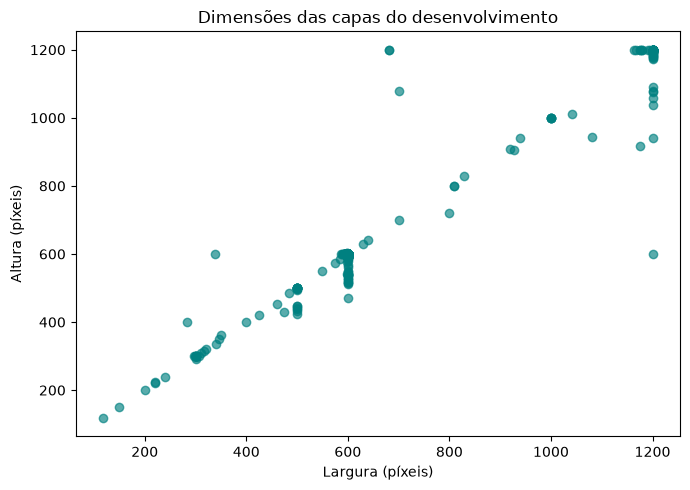

In [16]:
from PIL import Image

cover_paths = media_index("album_covers", ".jpg")
dev_songs = development.drop_duplicates("Audio_Song")
cover_rows = []
invalid_covers = []
for song in dev_songs["Audio_Song"]:
    path = cover_paths.get(song)
    if path is None:
        continue
    try:
        with Image.open(path) as image:
            width, height = image.size
            image.verify()
        cover_rows.append({"Audio_Song": song, "largura": width, "altura": height, "hash": sha256(path)})
    except (OSError, ValueError) as error:
        invalid_covers.append({"Audio_Song": song, "erro": str(error)})
cover_dimensions = pd.DataFrame(cover_rows)
print(f"Capas em falta: {dev_songs['Audio_Song'].isin(cover_paths).eq(False).sum()} | capas ilegíveis: {len(invalid_covers)} | capas válidas: {len(cover_dimensions)}")
print(f"Ficheiros de capa duplicados por conteúdo: {int(cover_dimensions['hash'].duplicated().sum()) if len(cover_dimensions) else 0}")
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cover_dimensions["largura"], cover_dimensions["altura"], alpha=.65, color="teal")
ax.set(xlabel="Largura (píxeis)", ylabel="Altura (píxeis)", title="Dimensões das capas do desenvolvimento")
fig.tight_layout()
plt.show()

**Interpretação:** a verificação distingue capas em falta, ficheiros ilegíveis e imagens repetidas. A ausência de capa é permitida pelo dicionário, por isso não justifica remover uma música.

In [ ]:
import subprocess
import imageio_ffmpeg

sample_rate = 11025
ffmpeg = imageio_ffmpeg.get_ffmpeg_exe()
audio_rows = []
example_signal = None
example_song = None
for song in dev_songs["Audio_Song"]:
    path = audio_paths.get(song)
    if path is None:
        raise FileNotFoundError(f"Ficheiro de áudio em falta para {song}.")
    decoded = subprocess.run(
        [ffmpeg, "-v", "error", "-i", str(path), "-ac", "1", "-ar", str(sample_rate), "-f", "f32le", "pipe:1"],
        check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE,
    )
    signal = np.frombuffer(decoded.stdout, dtype="<f4")
    if not len(signal):
        raise ValueError(f"O ficheiro de áudio {song} não produziu amostras.")
    audio_rows.append({
        "Audio_Song": song,
        "duração (s)": len(signal) / sample_rate,
        "energia média": float(np.mean(signal ** 2)),
        "RMS": float(np.sqrt(np.mean(signal ** 2))),
        "amplitude máxima": float(np.max(np.abs(signal))),
        "taxa de cruzamentos por zero": float(np.mean(np.signbit(signal[1:]) != np.signbit(signal[:-1]))),
    })
    if example_signal is None:
        example_signal, example_song = signal[:4 * sample_rate].copy(), song
audio_stats = pd.DataFrame(audio_rows)
display(audio_stats.drop(columns="Audio_Song").describe().T.round(4))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column, color in zip(axes.flat, ["energia média", "RMS", "amplitude máxima", "taxa de cruzamentos por zero"], ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    ax.hist(audio_stats[column], bins=25, color=color, edgecolor="white")
    ax.set(title=column, xlabel=column, ylabel="Número de músicas")
fig.tight_layout()
plt.show()

sample_index = np.arange(len(example_signal))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(sample_index, example_signal)
axes[0].set(title=f"Primeiros quatro segundos de {example_song} — amostras", xlabel="Índice da amostra", ylabel="Amplitude relativa")
axes[1].plot(sample_index / sample_rate, example_signal)
axes[1].set(title=f"Primeiros quatro segundos de {example_song} — tempo", xlabel="Tempo (s)", ylabel="Amplitude relativa")
fig.tight_layout()
plt.show()

**Interpretação:** as distribuições resumem a duração e quatro medidas do sinal de cada excerto. A energia média é a média do quadrado da amplitude; o RMS resume o nível do sinal. O exemplo mostra o mesmo trecho por índice de amostra e por tempo, como combinado. Estas estatísticas descrevem os ficheiros, mas não confirmam por si só que o áudio corresponde à música indicada.

## 4.6 Conjunto limpo e custo das decisões

Aplicamos as mesmas regras ao desenvolvimento e ao teste. Valores de referência para imputação são calculados apenas no desenvolvimento; casos ambíguos e outliers apenas estatísticos são mantidos.

In [ ]:
def clean_partition(frame, relevance_median, year_by_artist, year_median):
    cleaned = frame.drop_duplicates().copy()
    cleaned["Duration_missing"] = cleaned["Duration"].isna().astype("int8")
    duration = pd.to_numeric(cleaned["Duration"], errors="coerce")
    duration = duration.mask(duration.le(0) | duration.eq(9999))
    duration = duration.mask(duration.gt(10000), duration / 1000)
    minute_values = duration.between(0, 10, inclusive="neither")
    duration = duration.mask(minute_values, duration * 60)
    cleaned["Duration"] = duration
    cleaned["Duration_missing"] = cleaned["Duration_missing"] | duration.isna().astype("int8")

    year = pd.to_numeric(cleaned["ActualYear"], errors="coerce")
    invalid_year = year.le(0) | year.eq(9999) | year.gt(2026)
    year = year.mask(invalid_year)
    lowest = extract_year(cleaned["LowestYear"])
    year = year.mask(year.lt(lowest))
    cleaned["ActualYear_missing"] = year.isna().astype("int8")
    year_fill = cleaned["Artist"].map(year_by_artist).fillna(year_median)
    cleaned["ActualYear"] = year

    relevance = pd.to_numeric(cleaned["Relevance"], errors="coerce")
    relevance = relevance.mask(relevance.le(0))
    cleaned["Relevance_missing"] = relevance.isna().astype("int8")
    cleaned["Relevance"] = relevance
    cleaned["Genres_missing"] = cleaned["Genres"].isna().astype("int8")
    cleaned["Genres"] = cleaned["Genres"].fillna("[em falta]")

    for column in ["Artist", "Title"]:
        cleaned[column] = cleaned[column].astype("string").str.normalize("NFC").str.strip().str.replace(r"\s+", " ", regex=True)
    for column in ["Year", "LowestYear"]:
        cleaned[f"{column}_year"] = extract_year(cleaned[column])

    for tags, weights in weight_pairs:
        tag_count = cleaned[tags].map(count_nonempty_items)
        weight_count = cleaned[weights].map(count_nonempty_items)
        mismatch = tag_count.ne(weight_count) & (tag_count.gt(0) | weight_count.gt(0))
        cleaned.loc[mismatch, weights] = np.nan
    return cleaned

dev_for_fit = development.drop_duplicates().copy()
dev_year = pd.to_numeric(dev_for_fit["ActualYear"], errors="coerce")
dev_year = dev_year.mask(dev_year.le(0) | dev_year.eq(9999) | dev_year.gt(2026))
dev_year = dev_year.mask(dev_year.lt(extract_year(dev_for_fit["LowestYear"])))
year_by_artist = dev_year.groupby(dev_for_fit["Artist"]).median()
year_median = float(dev_year.median())
relevance_valid = pd.to_numeric(dev_for_fit["Relevance"], errors="coerce")
relevance_median = float(relevance_valid.mask(relevance_valid.le(0)).median())

test_audio_hashes = unique_songs.loc[unique_songs["split"].eq("teste"), "audio_hash"].dropna().unique()
development_audio_copy_ids = unique_songs.loc[
    unique_songs["split"].eq("desenvolvimento") & unique_songs["audio_hash"].isin(test_audio_hashes), "Audio_Song"
]
development_audio_candidates = unique_songs.loc[
    unique_songs["split"].eq("desenvolvimento") & ~unique_songs["Audio_Song"].isin(development_audio_copy_ids)
].dropna(subset="audio_hash")
development_duplicate_audio_ids = development_audio_candidates.loc[
    development_audio_candidates.duplicated("audio_hash", keep="first"), "Audio_Song"
]
development_ids_to_remove = pd.Index(development_audio_copy_ids).union(development_duplicate_audio_ids)
development_for_cleaning = development.loc[~development["Audio_Song"].isin(development_ids_to_remove)].copy()
cleaned_development = clean_partition(development_for_cleaning, relevance_median, year_by_artist, year_median)
cleaned_test = clean_partition(test, relevance_median, year_by_artist, year_median)
cleaned_dir = Path.cwd() / "outputs"
cleaned_dir.mkdir(parents=True, exist_ok=True)
cleaned_development.to_csv(cleaned_dir / "metadata_cleaned_development.csv", index=False)
cleaned_test.to_csv(cleaned_dir / "metadata_cleaned_test.csv", index=False)

costs = pd.DataFrame([
    {"decisão": "Remover linhas exatamente repetidas", "desenvolvimento": len(development) - len(development.drop_duplicates()), "informação perdida": "Nenhuma informação distinta"},
    {"decisão": "Retirar do desenvolvimento gravações de áudio repetidas", "desenvolvimento": int(len(development_audio_copy_ids) + len(development_duplicate_audio_ids)), "informação perdida": "Cópias redundantes; preserva-se um registo por gravação"},
    {"decisão": "Converter milissegundos/minutos em segundos", "desenvolvimento": int(duration_raw.gt(10000).sum() + duration_raw.between(0, 10, inclusive="neither").sum()), "informação perdida": "Nenhuma; muda-se a unidade"},
    {"decisão": "Marcar durações inválidas como em falta", "desenvolvimento": int((duration_raw.le(0) | duration_raw.eq(9999)).sum()), "informação perdida": "O valor inválido é substituído por ausência"},
    {"decisão": "Marcar Relevance inválida/em falta; imputar dentro dos folds", "desenvolvimento": int(development["Relevance"].isna().sum()), "informação perdida": "Incerteza original assinalada por Relevance_missing"},
    {"decisão": "Marcar ActualYear inválido/em falta; imputar dentro dos folds", "desenvolvimento": int(dev_year.isna().sum()), "informação perdida": "Incerteza original assinalada por ActualYear_missing"},
    {"decisão": "Preservar Duration em falta e as etiquetas em falta", "desenvolvimento": int(development["Duration"].isna().sum() + development["Genres"].isna().sum()), "informação perdida": "Nenhuma; criam-se indicadores"},
    ])
display(costs)
print(f"Desenvolvimento: {len(development)} para {len(cleaned_development)} linhas; teste: {len(test)} para {len(cleaned_test)} linhas.")
print(f"Ficheiros guardados em {cleaned_dir}.")

A limpeza corrige regras fixas e retira cópias de áudio do desenvolvimento. Relevance e ActualYear continuam sem imputação estatística nesta fase: a mediana é ajustada dentro de cada fold da pipeline. As hipóteses de conversão de unidades precisam de confirmação pela documentação ou fonte. Os custos devem ser revistos após a execução.

# 5. Distribuição das classes

Comparamos a distribuição do quadrante antes e depois da limpeza. A accuracy de uma previsão que escolhe sempre a classe maior serve de referência; com classes desequilibradas, também devemos avaliar macro-F1, balanced accuracy e recall por classe.

In [ ]:
quadrants = ["Q1", "Q2", "Q3", "Q4"]
before_counts = development["Quadrant"].value_counts().reindex(quadrants, fill_value=0)
after_counts = cleaned_development["Quadrant"].value_counts().reindex(quadrants, fill_value=0)
class_distribution = pd.DataFrame({"antes da limpeza": before_counts, "depois da limpeza": after_counts})
class_distribution["diferença"] = class_distribution["depois da limpeza"] - class_distribution["antes da limpeza"]
display(class_distribution)

largest = int(after_counts.max())
smallest = int(after_counts[after_counts.gt(0)].min())
majority_accuracy = largest / after_counts.sum()
majority_macro_f1 = (2 * majority_accuracy / (1 + majority_accuracy)) / len(quadrants)
print(f"Razão entre a maior e a menor classe após a limpeza: {largest}:{smallest} = {largest / smallest:.2f}:1.")
print(f"Prever sempre {after_counts.idxmax()} dá accuracy={majority_accuracy:.3f}, macro-F1={majority_macro_f1:.3f} e balanced accuracy={1 / len(quadrants):.3f}.")

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(quadrants))
width = .36
ax.bar(x - width / 2, before_counts, width, label="Antes", color="slateblue")
ax.bar(x + width / 2, after_counts, width, label="Depois", color="darkorange")
ax.set(xticks=x, xticklabels=quadrants, xlabel="Quadrante", ylabel="Número de linhas", title="Distribuição das classes antes e depois da limpeza")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretação:** a tabela e o gráfico mostram se as decisões de limpeza alteraram mais algumas classes do que outras. A accuracy da classe maior é uma referência simples, não um resultado suficiente: um modelo que ignore as classes pequenas pode ter accuracy razoável e falhar nelas. Por isso, na avaliação devemos reportar macro-F1, balanced accuracy e recall de cada quadrante.

## Síntese da avaliação: perguntas 4 e 5

Na pergunta 4 procurámos duplicados, estudámos os padrões de ausência, verificámos regras de validade entre colunas, comparámos métodos de outliers e inspecionámos as capas e o áudio. A tabela de custos regista que registos foram removidos ou corrigidos e que incerteza se conservou. As decisões de limpeza são definidas no desenvolvimento e aplicadas ao teste sem recalcular as imputações neste último.

Na pergunta 5 comparamos as contagens dos quatro quadrantes antes e depois da limpeza e calculamos a razão entre a maior e a menor classe e a baseline maioritária. Antes da limpeza, o desenvolvimento tinha Q1=374, Q2=112, Q3=356 e Q4=90: Q1 era a classe maioritária, Q4 a mais pequena e a razão era 4,16:1. Prever sempre Q1 acertava em cerca de 40,1% dos registos; essa accuracy não informa se as classes minoritárias são reconhecidas. O gráfico e a tabela acima mostram se a limpeza alterou estas proporções; a macro-F1, a balanced accuracy e o recall por quadrante são métricas mais informativas para comparar classificadores.

# 6. Avaliação da limpeza

Usamos a verdade-terreno apenas depois de definir as regras. Assim medimos o desempenho das decisões sem deixar que os defeitos artificiais orientem a limpeza.

## 6.1 Detetores de erros e outliers

Comparamos as regras de validade e quatro detetores com as alterações registadas em `truth/`. A precisão mede a proporção de sinalizações confirmadas; o recall mede a proporção de alterações encontradas.

In [ ]:
from sklearn.metrics import precision_recall_curve

truth_dir = Path.cwd() / "dataset" / "build" / "MERGE_ECAC" / "truth"
truth_cells = pd.read_csv(truth_dir / "truth_cells.csv", dtype={"song_id": "string", "defect_code": "string"})
truth_rows = pd.read_csv(truth_dir / "truth_rows.csv", dtype={"song_id": "string", "defect_code": "string"})
required_truth_columns = {"song_id", "column", "defect_code"}
if not required_truth_columns.issubset(truth_cells.columns):
    raise ValueError(f"Colunas em falta em truth_cells.csv: {sorted(required_truth_columns - set(truth_cells.columns))}")

evaluation_songs = development.drop_duplicates("Audio_Song").reset_index(drop=True)
song_ids = evaluation_songs["Audio_Song"].astype("string")
truth_cells_dev = truth_cells.loc[truth_cells["song_id"].isin(song_ids)].copy()
truth_rows_dev = truth_rows.loc[truth_rows["song_id"].isin(song_ids)].copy()
truth_songs_by_code = {
    code: set(truth_cells_dev.loc[truth_cells_dev["defect_code"].eq(code), "song_id"])
    for code in truth_cells_dev["defect_code"].dropna().unique()
}

raw_numeric = evaluation_songs[["Duration", "Relevance", "ActualYear", "Sample"]].apply(pd.to_numeric, errors="coerce")
duration = raw_numeric["Duration"].mask(raw_numeric["Duration"].le(0) | raw_numeric["Duration"].eq(9999))
duration = duration.mask(duration.gt(10000), duration / 1000)
duration = duration.mask(duration.between(0, 10, inclusive="neither"), duration * 60)
actual_year = raw_numeric["ActualYear"].mask(
    raw_numeric["ActualYear"].le(0) | raw_numeric["ActualYear"].eq(9999) | raw_numeric["ActualYear"].gt(2026)
)
feature_values = pd.DataFrame({"Duration": duration, "Relevance": raw_numeric["Relevance"], "ActualYear": actual_year, "Sample": raw_numeric["Sample"]})

outlier_flags = pd.DataFrame(index=evaluation_songs.index)
for detector in ["z-score", "MAD modificado", "Tukey (IQR)"]:
    outlier_flags[detector] = False
for column in feature_values:
    values = feature_values[column]
    present = values.dropna()
    if len(present) < 2:
        continue
    standard_deviation = present.std(ddof=0)
    if standard_deviation > 0:
        outlier_flags["z-score"] |= ((values - present.mean()).abs() / standard_deviation).gt(3).fillna(False)
    median = present.median()
    mad = (present - median).abs().median()
    if mad > 0:
        outlier_flags["MAD modificado"] |= (0.6745 * (values - median) / mad).abs().gt(3.5).fillna(False)
    q1, q3 = present.quantile([.25, .75])
    iqr = q3 - q1
    outlier_flags["Tukey (IQR)"] |= (values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)).fillna(False)

cluster_values = np.asarray(
    RobustScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(feature_values[["Duration", "Relevance", "ActualYear"]])),
    dtype=float,
)
outlier_flags["DBSCAN"] = DBSCAN(eps=eps_choice, min_samples=6).fit_predict(cluster_values) == -1
nearest_distance = NearestNeighbors(n_neighbors=2).fit(cluster_values).kneighbors(cluster_values)[0][:, 1]

rule_values = pd.DataFrame(index=evaluation_songs.index)
rule_values["Duration_ms"] = raw_numeric["Duration"].gt(10000) & raw_numeric["Duration"].le(1_000_000)
rule_values["Duration_min"] = raw_numeric["Duration"].gt(0) & raw_numeric["Duration"].lt(10)
rule_values["sentinela"] = evaluation_songs.select_dtypes(include="number").isin([-1, 999, 9999]).any(axis=1)
rule_values["ActualYear_futuro"] = raw_numeric["ActualYear"].gt(2026)
rule_values["ActualYear_contraditório"] = raw_numeric["ActualYear"].lt(extract_year(evaluation_songs["LowestYear"]))
for tags, weights in weight_pairs:
    mismatch = evaluation_songs[tags].map(count_nonempty_items).ne(evaluation_songs[weights].map(count_nonempty_items))
    rule_values["etiquetas_pesos"] = rule_values.get("etiquetas_pesos", pd.Series(False, index=evaluation_songs.index)) | mismatch

rule_for_code = {"C1": "Duration_ms", "C2": "Duration_min", "C3": "sentinela", "C4": "ActualYear_futuro", "C6": "ActualYear_contraditório", "C7": "etiquetas_pesos"}
evaluation_rows = []
for code, rule in rule_for_code.items():
    actual = song_ids.isin(truth_songs_by_code.get(code, set())).to_numpy()
    predicted = rule_values[rule].fillna(False).to_numpy(dtype=bool)
    tp = int((actual & predicted).sum())
    fp = int((~actual & predicted).sum())
    fn = int((actual & ~predicted).sum())
    evaluation_rows.append({"família": code, "detetor": rule, "verdadeiros positivos": tp, "falsos positivos": fp, "não detetados": fn, "precisão": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan})

for code in [f"H{i}" for i in range(1, 6)]:
    actual = song_ids.isin(truth_songs_by_code.get(code, set())).to_numpy()
    for detector in outlier_flags.columns:
        predicted = outlier_flags[detector].to_numpy(dtype=bool)
        tp = int((actual & predicted).sum())
        fp = int((~actual & predicted).sum())
        fn = int((actual & ~predicted).sum())
        evaluation_rows.append({"família": code, "detetor": detector, "verdadeiros positivos": tp, "falsos positivos": fp, "não detetados": fn, "precisão": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn) if tp + fn else np.nan})

detector_evaluation = pd.DataFrame(evaluation_rows)
display(detector_evaluation.round(3))
print(f"Músicas avaliadas: {len(evaluation_songs)} | alterações de células na verdade-terreno: {len(truth_cells_dev)} | alterações de linhas: {len(truth_rows_dev)}.")

outlier_truth = song_ids.isin(set().union(*(truth_songs_by_code.get(f"H{i}", set()) for i in range(1, 6)))).to_numpy()
if outlier_truth.any():
    precision_values, recall_values, thresholds = precision_recall_curve(outlier_truth, nearest_distance)
    threshold_index = int(np.argmin(np.abs(thresholds - np.quantile(nearest_distance, .99)))) if len(thresholds) else 0
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(recall_values, precision_values, color="slateblue")
    ax.scatter(recall_values[threshold_index], precision_values[threshold_index], color="darkorange", label="Limiar do percentil 99")
    ax.set(xlabel="Recall", ylabel="Precisão", xlim=(0, 1), ylim=(0, 1.02), title="Precisão-recall dos outliers injetados")
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print("Não há outliers H1–H5 no desenvolvimento para calcular a curva precisão-recall.")

**Interpretação:** a tabela separa alterações encontradas, falsos alarmes e alterações não detetadas. Precisão baixa indica muitas sinalizações sem confirmação; recall baixo mostra defeitos que escaparam. A curva compara limiares para a distância, sem a verdade-terreno influenciar a escolha da regra.

## 6.2 Revisão de até dez registos sinalizados

Inspecionamos casos assinalados que não constam da verdade-terreno. A indicação de erro objetivo ou extremo é uma triagem baseada nas regras do dicionário, não uma decisão automática de remoção.

In [ ]:
injected_ids = set(truth_cells["song_id"].dropna()) | set(truth_rows["song_id"].dropna())
any_flag = outlier_flags.any(axis=1).fillna(False).to_numpy(dtype=bool) | rule_values.any(axis=1).fillna(False).to_numpy(dtype=bool)
candidate_mask = any_flag & ~song_ids.isin(injected_ids).to_numpy()
candidate_indices = np.flatnonzero(candidate_mask)
candidate_scores = pd.DataFrame({"posição": candidate_indices, "distância": nearest_distance[candidate_indices]})
candidate_scores = candidate_scores.sort_values("distância", ascending=False).head(10)
verdict_rows = []
for row_index in candidate_scores["posição"]:
    row = evaluation_songs.iloc[int(row_index)]
    year_value = pd.to_numeric(pd.Series([row["ActualYear"]]), errors="coerce").iloc[0]
    lowest_value = extract_year(pd.Series([row["LowestYear"]])).iloc[0]
    duration_value = pd.to_numeric(pd.Series([row["Duration"]]), errors="coerce").iloc[0]
    relevance_value = pd.to_numeric(pd.Series([row["Relevance"]]), errors="coerce").iloc[0]
    objective_error = (
        (pd.notna(duration_value) and duration_value <= 0)
        or (pd.notna(relevance_value) and relevance_value <= 0)
        or (pd.notna(year_value) and (year_value <= 0 or year_value > 2026 or (pd.notna(lowest_value) and year_value < lowest_value)))
    )
    if objective_error:
        verdict, reason = "Erro objetivo", "Viola uma regra de validade do dicionário."
    elif outlier_flags.loc[int(row_index), ["z-score", "MAD modificado", "Tukey (IQR)" ]].any():
        verdict, reason = "Extremo potencialmente legítimo", "O valor é extremo; deve confirmar-se a fonte antes de o corrigir."
    else:
        verdict, reason = "Combinação rara", "Os valores parecem plausíveis isoladamente, mas a combinação é distante."
    active_detectors = list(outlier_flags.columns[outlier_flags.iloc[int(row_index)].to_numpy()])
    active_detectors.extend(rule_values.columns[rule_values.iloc[int(row_index)].fillna(False).to_numpy(dtype=bool)])
    verdict_rows.append({"Audio_Song": row["Audio_Song"], "Quadrant": row["Quadrant"], "Artist": row["Artist"], "Title": row["Title"], "Duration": row["Duration"], "Relevance": row["Relevance"], "ActualYear": row["ActualYear"], "detetores": ", ".join(active_detectors), "veredicto inicial": verdict, "justificação": reason})
review_candidates = pd.DataFrame(verdict_rows)
display(review_candidates)

**Interpretação:** estes casos não foram alterados artificialmente, por isso permitem discutir falsos alarmes plausíveis. Um extremo numa coluna não basta para o remover; violações claras do domínio justificam correção, enquanto combinações raras devem ser verificadas na fonte.

## 6.3 Comparação de imputações

A família B4 oculta valores de `Relevance` aleatoriamente. Usamos os valores originais guardados na verdade-terreno como referência e comparamos a mediana com k-NN, sem os incluir no ajuste.

In [ ]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

b4_cells = truth_cells_dev.loc[truth_cells_dev["defect_code"].eq("B4") & truth_cells_dev["column"].eq("Relevance"), ["song_id", "original_value"]].copy()
if b4_cells.empty:
    raise ValueError("Não há células B4 de Relevance no desenvolvimento para avaliar a imputação.")
b4_cells["original_value"] = pd.to_numeric(b4_cells["original_value"], errors="coerce")
b4_cells = b4_cells.dropna(subset="original_value").drop_duplicates("song_id").set_index("song_id")
b4_ids = b4_cells.index.astype("string")
numeric_columns = ["Duration", "Relevance", "ActualYear", "Sample"]
imputation_data = evaluation_songs.set_index(evaluation_songs["Audio_Song"].astype("string"))[numeric_columns].apply(pd.to_numeric, errors="coerce")
imputation_data["Duration"] = imputation_data["Duration"].mask(imputation_data["Duration"].le(0) | imputation_data["Duration"].eq(9999))
imputation_data["Duration"] = imputation_data["Duration"].mask(imputation_data["Duration"].gt(10000), imputation_data["Duration"] / 1000)
imputation_data["Duration"] = imputation_data["Duration"].mask(imputation_data["Duration"].between(0, 10, inclusive="neither"), imputation_data["Duration"] * 60)
imputation_data["ActualYear"] = imputation_data["ActualYear"].mask(imputation_data["ActualYear"].le(0) | imputation_data["ActualYear"].gt(2026))
reference_mask = ~imputation_data.index.isin(b4_ids)
reference = imputation_data.loc[reference_mask]
targets = imputation_data.loc[imputation_data.index.isin(b4_ids)]
if targets["Relevance"].notna().any():
    raise ValueError("Os valores B4 deveriam estar em falta no ficheiro usado para a avaliação.")

median_relevance = reference["Relevance"].median()
median_prediction = np.full(len(targets), median_relevance, dtype=float)
scaler = StandardScaler().fit(reference)
reference_scaled = scaler.transform(reference)
targets_scaled = scaler.transform(targets)
knn_imputer = KNNImputer(n_neighbors=5, weights="distance").fit(reference_scaled)
knn_values = knn_imputer.transform(targets_scaled)[:, numeric_columns.index("Relevance")]
knn_prediction = knn_values * scaler.scale_[numeric_columns.index("Relevance")] + scaler.mean_[numeric_columns.index("Relevance")]
truth_values = b4_cells.loc[targets.index, "original_value"].to_numpy(dtype=float)
imputation_results = []
for method, predictions in [("Mediana", median_prediction), ("k-NN", knn_prediction)]:
    imputation_results.append({"método": method, "MAE": np.mean(np.abs(truth_values - predictions)), "RMSE": np.sqrt(np.mean((truth_values - predictions) ** 2))})
imputation_scores = pd.DataFrame(imputation_results).set_index("método")
display(imputation_scores.round(4))
imputation_scores.plot(kind="bar", figsize=(7, 4), color=["slateblue", "darkorange"])
plt.ylabel("Erro de imputação")
plt.title("Imputação de Relevance nos valores B4 ocultados")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretação:** MAE e RMSE menores indicam imputações mais próximas dos valores originais B4. Esta comparação é específica de valores removidos aleatoriamente e não prova que o mesmo método seja melhor para ausências dependentes do valor, do artista ou do quadrante.

# 7. Classificador de referência: k-NN

Começamos pela pipeline exigida: colunas numéricas originais, imputação pela mediana, sem escala e k-NN. A avaliação usa cinco folds estratificados no desenvolvimento; cada configuração é escolhida apenas nos dados de treino do fold. O teste oficial não é usado nesta secção.

In [ ]:

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import pandas as pd

PARAM_GRID = {"knn__n_neighbors": list(range(1, 32, 2)),
              "knn__weights": ["uniform", "distance"],
              "knn__metric": ["euclidean", "manhattan"]}
evaluation_log = []

def take_rows(x, idx):
    return x.iloc[idx] if hasattr(x, "iloc") else np.asarray(x)[idx]

def canonical_artists(values):
    return (pd.Series(values).fillna("[artista em falta]").astype(str)
            .str.normalize("NFKC").str.casefold().str.strip()
            .str.replace(r"\s+", " ", regex=True).to_numpy())

def tune_pipeline(estimator, X, y, groups=None, seed=42):
    if groups is None:
        inner = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y))
    else:
        groups = canonical_artists(groups)
        inner = list(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(X, y, groups))
        for a, b in inner:
            assert not set(groups[a]) & set(groups[b])
    search = GridSearchCV(clone(estimator), PARAM_GRID, scoring="f1_macro",
                          cv=inner, n_jobs=-1, refit=True, error_score="raise")
    search.fit(X, y)
    return search

def nested_evaluate(estimator, X, y, folds, groups=None, name="condição", extra=None):
    y = np.asarray(y)
    groups = None if groups is None else canonical_artists(groups)
    predictions = np.empty(len(y), dtype=object)
    rows = []
    for number, (tr, va) in enumerate(folds, 1):
        Xt, yt = take_rows(X, tr), y[tr]
        gt = None if groups is None else groups[tr]
        if groups is not None:
            assert not set(groups[tr]) & set(groups[va]), "Artista nos dois lados do fold"
        if extra is not None:
            Xe, ye, ge = extra
            ge = canonical_artists(ge)
            allowed = ~np.isin(ge, groups[va])
            Xt = np.concatenate([np.asarray(Xt), np.asarray(Xe)[allowed]])
            yt = np.concatenate([yt, np.asarray(ye)[allowed]])
            gt = np.concatenate([gt, ge[allowed]])
        search = tune_pipeline(estimator, Xt, yt, gt, 100 + number)
        pred = search.predict(take_rows(X, va))
        predictions[va] = pred
        rows.append({"condição": name, "fold": number,
                     "accuracy": accuracy_score(y[va], pred),
                     "macro-F1": f1_score(y[va], pred, labels=["Q1","Q2","Q3","Q4"], average="macro", zero_division=0),
                     "hiperparâmetros": search.best_params_})
    frame = pd.DataFrame(rows)
    evaluation_log.extend(rows)
    return frame, predictions

def nested_scores(estimator, X, y, folds, groups, name):
    rows, _ = nested_evaluate(estimator, X, y, folds, groups, name)
    return rows["macro-F1"].to_numpy()

from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

model_development = development.drop_duplicates("Audio_Song").sort_values("Audio_Song").reset_index(drop=True)
target_columns = {"Valence", "Arousal", "Quadrant"}
numeric_features = [column for column in model_development.select_dtypes(include="number").columns if column not in target_columns]
if not numeric_features:
    raise ValueError("Não foram encontradas colunas numéricas para o classificador.")
if target_columns.intersection(numeric_features):
    raise ValueError("Uma variável-alvo foi incluída nos atributos do classificador.")
X_development = model_development[numeric_features].copy()
y_development = model_development["Quadrant"].astype(str)
groups_development = canonical_artists(model_development["Artist"])
quadrants = ["Q1", "Q2", "Q3", "Q4"]
if y_development.nunique() != 4 or y_development.isna().any():
    raise ValueError("É necessário ter as quatro classes no desenvolvimento.")
print(f"Desenvolvimento: {len(model_development)} músicas | atributos numéricos: {len(numeric_features)}.")

parameter_grid = {"knn__n_neighbors": list(range(1, 32, 2)), "knn__weights": ["uniform", "distance"], "knn__metric": ["euclidean", "manhattan"]}
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
outer_splits = list(outer_cv.split(X_development, y_development))

condition_results = []
for scale_features in [False, True]:
    condition = "imputação, sem escala" if not scale_features else "imputação e escala standard"
    for fold_number, (train_index, validation_index) in enumerate(outer_splits):
        X_train, X_validation = X_development.iloc[train_index], X_development.iloc[validation_index]
        y_train, y_validation = y_development.iloc[train_index], y_development.iloc[validation_index]
        inner_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + fold_number)
        inner_splits = list(inner_splitter.split(X_train, y_train))
        steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
        if scale_features:
            steps.append(("scaler", StandardScaler()))
        steps.append(("knn", KNeighborsClassifier()))
        search = GridSearchCV(Pipeline(steps), parameter_grid, scoring="f1_macro", cv=inner_splits, n_jobs=-1, error_score="raise")
        search.fit(X_train, y_train)
        predicted = search.predict(X_validation)
        condition_results.append({"condição": condition, "repetição": fold_number // 5 + 1, "fold": fold_number % 5 + 1, "accuracy": accuracy_score(y_validation, predicted), "macro-F1": f1_score(y_validation, predicted, labels=quadrants, average="macro", zero_division=0), "k escolhido": search.best_params_["knn__n_neighbors"], "métrica": search.best_params_["knn__metric"], "pesos": search.best_params_["knn__weights"]})

knn_cv = pd.DataFrame(condition_results)
cv_summary = knn_cv.groupby("condição").agg(accuracy_média=("accuracy", "mean"), accuracy_dp=("accuracy", "std"), macro_F1_média=("macro-F1", "mean"), macro_F1_dp=("macro-F1", "std")).sort_values("macro_F1_média", ascending=False)
display(cv_summary.round(3))
display(knn_cv.groupby(["condição", "k escolhido", "métrica", "pesos"]).size().rename("vezes selecionado").reset_index().sort_values(["condição", "vezes selecionado"], ascending=[True, False]))

baseline_rows = []
for fold_number, (train_index, validation_index) in enumerate(outer_splits):
    y_train, y_validation = y_development.iloc[train_index], y_development.iloc[validation_index]
    prediction = np.full(len(validation_index), y_train.value_counts().idxmax())
    baseline_rows.append({"accuracy": accuracy_score(y_validation, prediction), "macro-F1": f1_score(y_validation, prediction, labels=quadrants, average="macro", zero_division=0)})
baseline_cv = pd.DataFrame(baseline_rows)
print("Baseline maioritária nas mesmas partições:")
display(baseline_cv.agg(["mean", "std"]).round(3))

fixed_k_rows = []
for train_index, validation_index in outer_splits:
    fixed_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean", weights="uniform")),
    ])
    fixed_model.fit(X_development.iloc[train_index], y_development.iloc[train_index])
    fixed_prediction = fixed_model.predict(X_development.iloc[validation_index])
    fixed_k_rows.append({"accuracy": accuracy_score(y_development.iloc[validation_index], fixed_prediction), "macro-F1": f1_score(y_development.iloc[validation_index], fixed_prediction, labels=quadrants, average="macro", zero_division=0)})
print("Referência k=5, distância euclidiana, pesos uniformes, sem escala:")
display(pd.DataFrame(fixed_k_rows).agg(["mean", "std"]).round(3))

best_condition = cv_summary.index[0]
best_rows = knn_cv.loc[knn_cv["condição"].eq(best_condition)]
chosen_parameters = {"n_neighbors": int(best_rows["k escolhido"].mode().iloc[0]), "metric": best_rows["métrica"].mode().iloc[0], "weights": best_rows["pesos"].mode().iloc[0]}
final_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
if best_condition == "imputação e escala standard":
    final_steps.append(("scaler", StandardScaler()))
final_steps.append(("knn", KNeighborsClassifier(**chosen_parameters)))
final_model = Pipeline(final_steps)
print(f"Configuração de referência para as experiências seguintes: {best_condition}; parâmetros: {chosen_parameters}.")
print("O teste oficial fica reservado para a secção 14.")

**Interpretação:** comparamos a referência k=5 sem escala, a pesquisa interna dos hiperparâmetros e a baseline maioritária nos mesmos folds externos. A secção 8 testa separadamente a validação por artista; o teste oficial fica reservado para a secção 14.

## Síntese da avaliação: perguntas 6 e 7

Na pergunta 6 comparamos as regras e os detetores com as alterações registadas na verdade-terreno. As métricas mostram o que foi encontrado, o que escapou e que sinalizações não tinham confirmação. A revisão de casos não alterados distingue erros objetivos de extremos plausíveis; a comparação B4 avalia imputações usando valores ocultados ao acaso. Estes resultados medem apenas defeitos injetados e não provam que o restante conjunto esteja isento de problemas.

Na pergunta 7 comparamos k-NN com imputação mediana, sem escala, k=5 e pesquisa interna de hiperparâmetros; a baseline maioritária dá uma referência simples. O teste oficial permanece reservado. A validação estratificada por artista e a escolha do protocolo são discutidas na secção 8.

## 8. Protocolo de validação

Comparamos validação estratificada (artistas possivelmente partilhados) com validação estratificada agrupada por artista. Mantemos a mesma representação e grelha de pesquisa; otimizamos os hiperparâmetros dentro de cada fold para isolar o efeito da partilha de artistas. A aplicação pode receber artistas sem catálogo; por isso, a estimativa agrupada é a mais exigente e é usada nas experiências seguintes. Como o teste oficial não foi separado por artista e a secção 3.5 identifica sobreposição, a estimativa estratificada é a mais comparável ao teste.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

reference_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(**chosen_parameters)),
])
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
protocol_rows = []
for name, folds in [
    ("Estratificada", list(stratified_cv.split(X_development, y_development))),
    ("Artista-disjunta", list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X_development, y_development, groups_development))),
]:
    rows, _ = nested_evaluate(reference_pipeline, X_development, y_development, folds, None if name == "Estratificada" else groups_development, name)
    protocol_rows.append({"protocolo": name, "accuracy": rows["accuracy"].mean(), "macro-F1": rows["macro-F1"].mean(), "desvio": rows["macro-F1"].std()})
protocol_results = pd.DataFrame(protocol_rows).set_index("protocolo")
display(protocol_results.round(3))
print("Diferença (estratificada − artista-disjunta), macro-F1:", round(protocol_results.loc["Estratificada", "macro-F1"] - protocol_results.loc["Artista-disjunta", "macro-F1"], 3))

**Interpretação:** a diferença quantifica a sensibilidade à partilha de artistas; não é uma estimativa de desempenho universal. A divisão estratificada responde ao desempenho em músicas de artistas que podem já ser conhecidos; a divisão agrupada responde ao desempenho em artistas não vistos. A aplicação pode enfrentar ambos os cenários, mas a avaliação principal permanece agrupada para reduzir fuga de identidade.

## 9. Efeito do pré-processamento

Comparamos os passos de imputação, limpeza e escala numa validação por artista. A limpeza aplicada em 4 remove duplicados e corrige apenas regras documentadas; a imputação e a escala são ajustadas dentro de cada fold. As métricas são calculadas no mesmo conjunto de folds. Um passo que diminui o score pode ainda ser mantido para evitar informação inválida ou fuga entre partições.

In [ ]:
from sklearn.base import clone

clean_dev = cleaned_development.drop_duplicates("Audio_Song").sort_values("Audio_Song").reset_index(drop=True)
clean_numeric = clean_dev.select_dtypes(include="number").drop(columns=["Valence", "Arousal"], errors="ignore")
clean_target = clean_dev["Quadrant"].astype(str)
clean_groups = pd.Series(canonical_artists(clean_dev["Artist"]))
clean_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(clean_numeric, clean_target, clean_groups))
preprocess_conditions = {
    "Sem imputação (linhas completas)": Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(**chosen_parameters))]),
    "Imputação": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("knn", KNeighborsClassifier(**chosen_parameters))]),
    "Imputação + escala": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scale", StandardScaler()), ("knn", KNeighborsClassifier(**chosen_parameters))]),
}
preprocess_rows = []
for name, estimator in preprocess_conditions.items():
    if "Sem imputação" in name:
        valid = clean_numeric.notna().all(axis=1).to_numpy()
        X_part, y_part, g_part = clean_numeric.loc[valid], clean_target.loc[valid], clean_groups.loc[valid]
        groups_per_class = pd.DataFrame({"classe": y_part, "artista": g_part}).groupby("classe")["artista"].nunique()
        if len(X_part) < 5 or y_part.nunique() != 4 or g_part.nunique() < 5 or groups_per_class.min() < 5:
            print(f"{name}: não estimável com validação estratificada por artista; apenas {len(X_part)} linhas completas disponíveis.")
            preprocess_rows.append({"passo": name, "macro-F1": np.nan, "desvio": np.nan})
            continue
        folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(X_part, y_part, g_part))
    else:
        X_part, y_part, g_part, folds = clean_numeric, clean_target, clean_groups, clean_folds
    score = nested_scores(estimator, X_part, y_part, folds, g_part, name)
    preprocess_rows.append({"passo": name, "macro-F1": score.mean(), "desvio": score.std()})
preprocess_results = pd.DataFrame(preprocess_rows).set_index("passo")
raw_original = development.drop_duplicates("Audio_Song").copy()
raw_lookup = raw_original.set_index(raw_original["Audio_Song"].astype(str))
clean_ids = clean_dev["Audio_Song"].astype(str)
common_clean_columns = [c for c in clean_numeric.columns if c in raw_lookup.columns]
raw_common = raw_lookup.reindex(clean_ids)[common_clean_columns].apply(pd.to_numeric, errors="coerce")
clean_common = clean_numeric[common_clean_columns].reset_index(drop=True)
for name, matrix in [("Dados originais (colunas comuns)", raw_common.to_numpy(dtype=float)), ("Após limpeza (colunas comuns)", clean_common.to_numpy(dtype=float))]:
    score = nested_scores(Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scale", StandardScaler()), ("knn", KNeighborsClassifier(**chosen_parameters))]), matrix, clean_target, clean_folds, clean_groups, name)
    preprocess_results.loc[name] = {"macro-F1": score.mean(), "desvio": score.std()}
display(preprocess_results.round(3))
family_rows = []
raw_feature_groups = {"Duração (unidades/valores inválidos)": ["Duration"], "Datas/anos": ["Year", "LowestYear", "ActualYear"], "Relevância": ["Relevance"]}
for family, columns in raw_feature_groups.items():
    variant = clean_numeric.copy()
    for column in columns:
        if column in variant and column in raw_lookup:
            variant[column] = pd.to_numeric(raw_lookup.reindex(clean_ids)[column], errors="coerce").to_numpy()
    scores = nested_scores(Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scale", StandardScaler()), ("knn", KNeighborsClassifier(**chosen_parameters))]), variant, clean_target, clean_folds, clean_groups, family)
    family_rows.append({"família revertida": family, "macro-F1": scores.mean(), "diferença face a limpo": scores.mean() - preprocess_results.loc["Imputação + escala", "macro-F1"]})
display(pd.DataFrame(family_rows).round(3))
print("A escala afeta especialmente o k-NN: sem escala, atributos com unidades/variâncias maiores dominam as distâncias.")

**Interpretação:** a tabela mostra o score depois de cada tratamento; a comparação sem imputação usa apenas linhas completas e, por isso, também altera a amostra. A escala só deve ser aplicada depois da imputação. A limpeza não é desfeita para recuperar um aumento aparente: correções válidas e prevenção de duplicação são requisitos de integridade, não hiperparâmetros.

## 10. Representações

As características engenheiradas cobrem três modalidades. As associações com valência e arousal são calculadas apenas no desenvolvimento e são descritivas, não uma validação da teoria. Os embeddings são transformações de modelos públicos congelados; nenhuma cabeça é treinada nos dados deste projeto. O fitting de seletores, imputadores e projeções é feito exclusivamente dentro dos folds.

In [ ]:
import subprocess
import re
import ast
from pathlib import Path
from sklearn.preprocessing import MultiLabelBinarizer
import librosa
from PIL import Image, ImageStat
from scipy.stats import entropy

audio_files = {p.stem: p for p in (media_dir / "audio").rglob("*.mp3")}
lyric_files = {p.stem: p for p in (media_dir / "lyrics").rglob("*.txt")}
cover_files = {p.stem: p for p in (media_dir / "album_covers").rglob("*.jpg")}
original_metadata = pd.read_csv(data_dir.parent / "merge_original" / "metadata.csv")
known_ids = set(cleaned_development["Audio_Song"]) | set(cleaned_test["Audio_Song"])
subsampled_ids = set(truth_rows.loc[truth_rows["defect_code"].eq("F"), "song_id"].dropna().astype(str))
restored_raw = original_metadata.loc[original_metadata["Audio_Song"].astype(str).isin(subsampled_ids) & ~original_metadata["Audio_Song"].isin(test_ids)].copy()
cleaned_restored = clean_partition(restored_raw, relevance_median, year_by_artist, year_median) if len(restored_raw) else cleaned_development.iloc[0:0].copy()
song_table = pd.concat([cleaned_development, cleaned_test, cleaned_restored], ignore_index=True).drop_duplicates("Audio_Song")

def audio_features(path):
    raw = subprocess.run([ffmpeg, "-v", "error", "-i", str(path), "-t", "30", "-ac", "1", "-ar", "22050", "-f", "f32le", "pipe:1"], check=True, capture_output=True).stdout
    y = np.frombuffer(raw, dtype="<f4")
    if not len(y):
        raise ValueError(f"Áudio vazio: {path}")
    S = np.abs(librosa.stft(y, n_fft=2048, hop_length=512))
    mfcc = librosa.feature.mfcc(y=y, sr=22050, n_mfcc=13, n_fft=2048, hop_length=512)
    chroma = librosa.feature.chroma_stft(y=y, sr=22050, n_fft=2048, hop_length=512)
    onset = librosa.onset.onset_strength(y=y, sr=22050)
    tempo = librosa.feature.tempo(onset_envelope=onset, sr=22050)
    return {
        "a_mfcc_mean": float(mfcc.mean()), "a_mfcc_std": float(mfcc.std()),
        "a_chroma_mean": float(chroma.mean()), "a_chroma_std": float(chroma.std()),
        "a_tempo": float(tempo[0]), "a_onset_mean": float(onset.mean()),
        "a_rms_mean": float(librosa.feature.rms(y=y).mean()),
        "a_zcr": float(librosa.feature.zero_crossing_rate(y).mean()),
        "a_centroid": float(librosa.feature.spectral_centroid(S=S, sr=22050).mean()),
        "a_bandwidth": float(librosa.feature.spectral_bandwidth(S=S, sr=22050).mean()),
        "a_rolloff": float(librosa.feature.spectral_rolloff(S=S, sr=22050).mean()),
        "a_flatness": float(librosa.feature.spectral_flatness(S=S).mean()),
        "a_flux": float(np.diff(S, axis=1).clip(0).mean()),
    }

def lyric_features(path):
    text = path.read_text(encoding="utf-8", errors="replace")
    words = re.findall(r"\b[\w']+\b", text.lower())
    counts = pd.Series(words).value_counts()
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    return {
        "l_words": len(words), "l_unique_ratio": len(counts) / max(len(words), 1),
        "l_mean_word_length": float(np.mean([len(w) for w in words])) if words else 0,
        "l_mean_line_words": float(np.mean([len(line.split()) for line in lines])) if lines else 0,
        "l_repetition": float(1 - len(counts) / max(len(words), 1)),
        "l_exclamation": text.count("!"), "l_question": text.count("?"),
        "l_upper_ratio": sum(c.isupper() for c in text) / max(len(text), 1),
        "l_verse_count": len(lines), "l_punctuation": sum(c in "!?.,;:" for c in text) / max(len(text), 1),
        "l_positive_lexicon": sum(w in {"love", "happy", "joy", "good", "light"} for w in words),
        "l_negative_lexicon": sum(w in {"hate", "sad", "pain", "dark", "alone"} for w in words),
    }

def cover_features(path):
    image = np.asarray(Image.open(path).convert("RGB").resize((224, 224)), dtype=np.float32) / 255
    gray = image.mean(axis=2)
    edge = np.abs(np.diff(gray, axis=0)).mean() + np.abs(np.diff(gray, axis=1)).mean()
    hist = np.histogram(gray, bins=16, range=(0, 1), density=True)[0]
    return {**{f"c_rgb_{i}_mean": float(image[:, :, i].mean()) for i in range(3)},
            **{f"c_rgb_{i}_std": float(image[:, :, i].std()) for i in range(3)},
            "c_brightness": float(gray.mean()), "c_contrast": float(gray.std()),
            "c_entropy": float(entropy(hist + 1e-12)), "c_edge_density": float(edge),
            "c_center_brightness": float(gray[56:168, 56:168].mean()),
            "c_border_brightness": float(np.concatenate([gray[:28].ravel(), gray[-28:].ravel(), gray[:, :28].ravel(), gray[:, -28:].ravel()]).mean())}

missing_audio = set(song_table["Audio_Song"].astype(str)) - set(audio_files)
missing_lyrics = set(song_table["Lyric_Song"].astype(str)) - set(lyric_files)
if missing_audio or missing_lyrics:
    raise FileNotFoundError(f"Ficheiros obrigatórios em falta: áudio={len(missing_audio)}, letras={len(missing_lyrics)}.")

engineered_rows = []
for row in song_table.itertuples(index=False):
    sid = str(getattr(row, "Audio_Song"))
    record = {"Audio_Song": sid}
    record.update(audio_features(audio_files[sid]))
    if sid in cover_files:
        record.update(cover_features(cover_files[sid]))
    lyric_id = str(getattr(row, "Lyric_Song", sid))
    record.update(lyric_features(lyric_files[lyric_id]))
    engineered_rows.append(record)
engineered_all = pd.DataFrame(engineered_rows).set_index("Audio_Song")
engineered_all.index = engineered_all.index.astype(str)
def parse_tags(value):
    if not isinstance(value, str) or not value.strip():
        return []
    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, (list, tuple, set)):
            return sorted({str(item).strip() for item in parsed if str(item).strip()})
    except (ValueError, SyntaxError):
        pass
    return sorted({item.strip() for item in re.split(r"[;,|]", value) if item.strip()})
metadata_exclude = {"Audio_Song", "Lyric_Song", "Quadrant", "Artist", "Title", "AllMusic Id", "SampleURL", "Sample", "Valence", "Arousal", "num_MoodsAll"}
metadata_numeric = song_table.select_dtypes(include="number").drop(columns=list(metadata_exclude), errors="ignore")
metadata_numeric.index = song_table["Audio_Song"].astype(str)
from sklearn.feature_extraction import FeatureHasher
TAG_HASH_SIZE = 32
metadata_parts = [metadata_numeric]
metadata_tag_encoders = {}
def hashed_tags(value):
    return FeatureHasher(n_features=TAG_HASH_SIZE, input_type="string", alternate_sign=False).transform([parse_tags(value)]).toarray()[0]
for tag_name in ["Genres", "Styles"]:
    if tag_name in song_table:
        tag_matrix = np.vstack([hashed_tags(v) for v in song_table[tag_name]])
        tag_matrix[song_table[tag_name].isna().to_numpy(), :] = np.nan
        metadata_parts.append(pd.DataFrame(tag_matrix, index=song_table["Audio_Song"].astype(str),
                                          columns=[f"tag_{tag_name}_hash_{i}" for i in range(TAG_HASH_SIZE)]))
metadata_features = pd.concat(metadata_parts, axis=1)
engineered_all = engineered_all.join(metadata_features, how="left")
dev_ids = set(cleaned_development["Audio_Song"].astype(str))
test_ids_clean = set(cleaned_test["Audio_Song"].astype(str))
engineered_dev = engineered_all.reindex(cleaned_development["Audio_Song"].astype(str))
engineered_test = engineered_all.reindex(cleaned_test["Audio_Song"].astype(str))
engineered_features = engineered_all.columns.tolist()
print(f"Features engenheiradas: {len(engineered_features)}; áudio={sum(c.startswith('a_') for c in engineered_features)}, letras={sum(c.startswith('l_') for c in engineered_features)}, capa={sum(c.startswith('c_') for c in engineered_features)}.")
display(pd.DataFrame([
    {"domínio": "Áudio", "grupos": "melodia/harmonia; ritmo; dinâmica; timbre; expressividade/textura", "cálculo": "MFCC/chroma (n_fft=2048, hop=512), tempo/onset, RMS, ZCR, espectro", "eixo esperado": "chroma→valência; tempo/RMS→arousal; timbre→misto", "perdas": "média/variabilidade em excerto até 30 s; perde forma global"},
    {"domínio": "Letras", "grupos": "conteúdo; estilo; estrutura; semântica aproximada", "cálculo": "contagens, diversidade, comprimento de linha, repetição e léxico simples", "eixo esperado": "léxico→valência; pontuação→arousal; restante→misto", "perdas": "léxico inglês pequeno; perde contexto, ironia e idioma"},
    {"domínio": "Capa", "grupos": "cor; textura; composição", "cálculo": "RGB/luminância, entropia (16 bins), diferenças de luminância e centro/borda", "eixo esperado": "brilho→valência; contraste/arestas→arousal; composição→misto", "perdas": "redimensionamento 224×224; perde detalhe"},
]))
av_for_dev = cleaned_development[["Audio_Song", "Lyric_Song"]].merge(av_values, on=["Audio_Song", "Lyric_Song"], how="left", validate="one_to_one")
av_for_dev.index = av_for_dev["Audio_Song"].astype(str)
feature_corr = engineered_dev.join(av_for_dev[["Valence", "Arousal"]], how="left")
display(feature_corr.corr(numeric_only=True)[["Valence", "Arousal"]].drop(index=["Valence", "Arousal"], errors="ignore").sort_values("Valence", key=lambda s: s.abs(), ascending=False).head(15).round(2))

**Interpretação:** as características descrevem sinal, texto e imagem; por modalidade, há pelo menos dez colunas e grupos distintos. A correlação de Pearson com `Valence`/`Arousal` é evidência associativa, não causal, e pode ser fraca quando o resumo simples não capta a estrutura emocional. Ausências de ficheiros permanecem em falta para imputação dentro do treino. `Genres` e `Styles` são codificados como multi-rótulo; `Moods` e `Themes` são excluídos por possível fuga semântica direta do alvo. O vocabulário de tags é ajustado no desenvolvimento.

In [ ]:
from transformers import AutoFeatureExtractor, AutoModel, AutoImageProcessor
from sentence_transformers import SentenceTransformer
import torch

MODEL_REVISIONS = {
    "audio": ("MIT/ast-finetuned-audioset-10-10-0.4593", "f826b80d28226b62986cc218e5cec390b1096902"),
    "lyrics": ("sentence-transformers/all-MiniLM-L6-v2", "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"),
    "cover": ("google/vit-base-patch16-224", "3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3"),
}
device = "cuda" if torch.cuda.is_available() else "cpu"
audio_processor = AutoFeatureExtractor.from_pretrained(MODEL_REVISIONS["audio"][0], revision=MODEL_REVISIONS["audio"][1])
audio_encoder = AutoModel.from_pretrained(MODEL_REVISIONS["audio"][0], revision=MODEL_REVISIONS["audio"][1]).to(device).eval()
text_encoder = SentenceTransformer(MODEL_REVISIONS["lyrics"][0], revision=MODEL_REVISIONS["lyrics"][1], device=device)
image_processor = AutoImageProcessor.from_pretrained(MODEL_REVISIONS["cover"][0], revision=MODEL_REVISIONS["cover"][1])
image_encoder = AutoModel.from_pretrained(MODEL_REVISIONS["cover"][0], revision=MODEL_REVISIONS["cover"][1]).to(device).eval()

def learned_audio(path):
    raw = subprocess.run([ffmpeg, "-v", "error", "-i", str(path), "-t", "10", "-ac", "1", "-ar", "16000", "-f", "f32le", "pipe:1"], check=True, capture_output=True).stdout
    waveform = np.frombuffer(raw, dtype="<f4")
    inputs = audio_processor(waveform, sampling_rate=16000, return_tensors="pt", padding=True, truncation=True)
    with torch.no_grad():
        return audio_encoder(**{k: v.to(device) for k, v in inputs.items()}).last_hidden_state[:, 0].cpu().numpy()[0]

def learned_cover(path):
    image = Image.open(path).convert("RGB")
    inputs = image_processor(images=image, return_tensors="pt")
    with torch.no_grad():
        return image_encoder(**{k: v.to(device) for k, v in inputs.items()}).last_hidden_state[:, 0].cpu().numpy()[0]

def read_lyrics(sid):
    return lyric_files[sid].read_text(encoding="utf-8", errors="replace") if sid in lyric_files else ""

lyric_ids = [str(getattr(row, "Lyric_Song", row.Audio_Song)) for row in song_table.itertuples(index=False)]
learned_text = text_encoder.encode([read_lyrics(s) for s in lyric_ids], normalize_embeddings=True, show_progress_bar=True)
for i, lyric_id in enumerate(lyric_ids):
    if lyric_id not in lyric_files: learned_text[i, :] = np.nan
learned_rows = []
for sid in song_table["Audio_Song"].astype(str):
    av = learned_audio(audio_files[sid]) if sid in audio_files else np.full(768, np.nan)
    cv = learned_cover(cover_files[sid]) if sid in cover_files else np.full(768, np.nan)
    learned_rows.append(np.concatenate([av, learned_text[len(learned_rows)], cv]))
learned_all = pd.DataFrame(learned_rows, index=song_table["Audio_Song"].astype(str))
learned_dev = learned_all.reindex(cleaned_development["Audio_Song"].astype(str))
learned_test = learned_all.reindex(cleaned_test["Audio_Song"].astype(str))
print("Dimensões por modalidade:", {"áudio": 768, "letras": 384, "capa": 768, "concatenação": learned_all.shape[1]})
display(pd.DataFrame([
    {"modalidade": "áudio", "modelo/revisão": MODEL_REVISIONS["audio"], "fonte": "https://huggingface.co/" + MODEL_REVISIONS["audio"][0], "tarefa": "AudioSet, classificação de eventos sonoros", "licença": "BSD-3-Clause"},
    {"modalidade": "letras", "modelo/revisão": MODEL_REVISIONS["lyrics"], "fonte": "https://huggingface.co/" + MODEL_REVISIONS["lyrics"][0], "tarefa": "similaridade semântica de frases", "licença": "Apache-2.0"},
    {"modalidade": "capa", "modelo/revisão": MODEL_REVISIONS["cover"], "fonte": "https://huggingface.co/" + MODEL_REVISIONS["cover"][0], "tarefa": "classificação de imagens ImageNet-21k/1k", "licença": "Apache-2.0"},
]))
print("Áudio: AudioSet (classificação de eventos sonoros); letras: pares de frases para similaridade semântica; capa: ImageNet-21k/1k para classificação visual. São tarefas indiretas face à emoção musical.")
print("Pré-processamento: áudio mono, 16 kHz, primeiro trecho de 10 s; texto tokenizado/truncado pelo encoder; imagem RGB redimensionada/cortada e normalizada pelo processor. Revisões fixas; sem fine-tuning.")
print("Os embeddings são determinísticos e não ajustam parâmetros ao conjunto; fitting supervisionado subsequente deve permanecer nos folds de desenvolvimento.")

**Interpretação:** os modelos e revisões estão fixados no código. AST prevê classes AudioSet, MiniLM representa similaridade semântica e ViT classifica objetos/imagens; nenhum foi treinado para quadrantes emocionais. O áudio perde a restante forma e mistura, letras truncam sequências longas e ViT perde resolução; embeddings não têm dimensões semanticamente interpretáveis. Estimativas não são produzidas até executar a extração local.

## 11. Seleção e transformação

As três seleções (filtro, wrapper e embedded) e as transformações são ajustadas no desenvolvimento. O embedded usa árvores, não k-NN; isso pode alterar a ordenação porque otimiza um critério/modelo diferente. Em 12, o filtro é repetido dentro de cada fold para evitar usar rótulos de validação. LDA supervisionada pode gerar no máximo `n_classes − 1 = 3` dimensões.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

engineered_matrix = engineered_dev.reindex(cleaned_development["Audio_Song"].astype(str)).reset_index(drop=True)
engineered_matrix = engineered_matrix.select_dtypes(include="number")
y_repr = cleaned_development["Quadrant"].astype(str).reset_index(drop=True)
X_repr = SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(engineered_matrix)
scaler_repr = StandardScaler().fit(X_repr)
X_scaled_repr = scaler_repr.transform(X_repr)
k_select = min(20, X_scaled_repr.shape[1])
filter_sel = SelectKBest(f_classif, k=k_select).fit(X_scaled_repr, y_repr)
wrapper_sel = RFE(LogisticRegression(max_iter=2000, class_weight="balanced"), n_features_to_select=k_select, step=0.2).fit(X_scaled_repr, y_repr)
embedded_sel = ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1).fit(X_scaled_repr, y_repr)
embedded_keep = np.argsort(embedded_sel.feature_importances_)[-k_select:]
selection_sets = {
    "Filtro (ANOVA)": set(engineered_matrix.columns[filter_sel.get_support()]),
    "Wrapper (RFE-logística)": set(engineered_matrix.columns[wrapper_sel.get_support()]),
    "Embedded (ExtraTrees)": set(engineered_matrix.columns[embedded_keep]),
}
selection_table = pd.DataFrame([{"método": name, "atributos": ", ".join(sorted(cols))} for name, cols in selection_sets.items()])
display(selection_table)
display(pd.Series(sorted(set.intersection(*selection_sets.values())), name="seleção comum").to_frame())
pca_repr = PCA(n_components=min(32, X_scaled_repr.shape[1]), random_state=42).fit(X_scaled_repr)
lda_repr = LinearDiscriminantAnalysis(n_components=min(3, y_repr.nunique() - 1)).fit(X_scaled_repr, y_repr)
display(pd.DataFrame({"componentes PCA": np.arange(1, len(pca_repr.explained_variance_ratio_) + 1), "variância acumulada": np.cumsum(pca_repr.explained_variance_ratio_)}).tail(8).round(3))
pca_2d = PCA(n_components=2, random_state=42).fit_transform(X_scaled_repr)
lda_2d = lda_repr.transform(X_scaled_repr)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label in quadrants:
    mask = y_repr.to_numpy() == label
    axes[0].scatter(pca_2d[mask, 0], pca_2d[mask, 1], s=18, alpha=.65, label=label)
    axes[1].scatter(lda_2d[mask, 0], lda_2d[mask, 1], s=18, alpha=.65, label=label)
axes[0].set_title("PCA (sem rótulos)")
axes[1].set_title("LDA (supervisionada)")
for ax in axes: ax.legend()
fig.tight_layout()
plt.show()
print(f"LDA: {lda_repr.transform(X_scaled_repr).shape[1]} dimensões para {y_repr.nunique()} classes; é supervisionada e deve ser ajustada dentro de cada fold.")
print("As coordenadas latentes de cada embedding são combinações distribuídas, não features isoladas; não as selecionamos por nome. Muitas dimensões em poucas centenas de exemplos tendem a concentrar distâncias, tornando vizinhos menos distintos.")

**Interpretação:** a interseção mostra o consenso empírico entre métodos; o wrapper custa mais por treinar repetidamente o estimador. PCA não usa rótulos; LDA usa e requer fit exclusivamente nos dados de treino de cada fold. Os componentes de um embedding são latentes, pelo que filtrar por uma coordenada isolada não tem interpretação robusta.

## 12. Representação contra tratamento

A grelha compara características engenheiradas, embeddings e concatenação, sob seleção, PCA e LDA. Todos os tratamentos são ajustados em cada treino de fold, com as mesmas dimensões-alvo; LDA só admite três. Normalizamos os blocos antes da concatenação para impedir que a dimensão/variância de um domínio domine. Reportamos score macro-F1 e tempo por célula; a distância euclidiana em espaço padronizado é a referência, enquanto a distância cosseno pode ser mais apropriada para embeddings normalizados.

In [ ]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import f1_score
import time

X_engineered = engineered_dev.reindex(cleaned_development["Audio_Song"].astype(str)).reset_index(drop=True).select_dtypes(include="number")
X_learned = learned_dev.reset_index(drop=True)
X_learned_array = X_learned.to_numpy(dtype=float)
X_both = np.concatenate([X_engineered.to_numpy(dtype=float), X_learned_array], axis=1)
n_engineered = X_engineered.shape[1]
X_by_representation = {"engenheirada": X_engineered.to_numpy(dtype=float), "aprendida": X_learned_array, "ambas": X_both}
y_grid = cleaned_development["Quadrant"].astype(str).reset_index(drop=True)
groups_grid = pd.Series(canonical_artists(cleaned_development["Artist"]))
grid_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(np.zeros(len(y_grid)), y_grid, groups_grid))
dimensions = [3, 8, 16, 32]
grid_rows = []
grid_best_estimators = {}
for rep_name, matrix in X_by_representation.items():
    for treatment in ["selecionada", "PCA", "LDA"]:
        dims = [3] if treatment == "LDA" else dimensions
        for dim in dims:
            if treatment == "selecionada":
                reducer = SelectKBest(f_classif, k=min(dim, matrix.shape[1]))
            elif treatment == "PCA":
                reducer = PCA(n_components=min(dim, matrix.shape[1]), random_state=42)
            else:
                reducer = LinearDiscriminantAnalysis(n_components=3)
            if rep_name == "ambas":
                from sklearn.compose import ColumnTransformer
                balanced_scale = ColumnTransformer([
                    ("engenheirada", StandardScaler(), list(range(n_engineered))),
                    ("aprendida", StandardScaler(), list(range(n_engineered, matrix.shape[1]))),
                ], transformer_weights={"engenheirada": 1 / np.sqrt(n_engineered), "aprendida": 1 / np.sqrt(matrix.shape[1] - n_engineered)})
            else:
                balanced_scale = StandardScaler()
            estimator = Pipeline([
                ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
                ("scale", balanced_scale),
                ("reduce", reducer),
                ("knn", KNeighborsClassifier(**chosen_parameters)),
            ])
            started = time.perf_counter()
            scores = nested_scores(estimator, matrix, y_grid, grid_folds, groups_grid, f"{rep_name}/{treatment}/{dim}")
            elapsed = time.perf_counter() - started
            grid_rows.append({"representação": rep_name, "tratamento": treatment, "dimensão": dim, "macro-F1": scores.mean(), "desvio": scores.std(), "segundos": elapsed})
            grid_best_estimators[(rep_name, treatment, dim)] = estimator
representation_grid = pd.DataFrame(grid_rows)
display(representation_grid.pivot_table(index=["representação", "tratamento"], columns="dimensão", values="macro-F1").round(3))
display(representation_grid.sort_values("macro-F1", ascending=False).head(10).round(3))
grid_winner = representation_grid.sort_values("macro-F1", ascending=False).iloc[0]
winner_key = (grid_winner["representação"], grid_winner["tratamento"], int(grid_winner["dimensão"]))
print("Melhor célula de validação:", winner_key, "| score:", round(grid_winner["macro-F1"], 3))
domain_rows = []
for prefix in ["a_", "l_", "c_"]:
    domain_engineered = engineered_dev.filter(regex=f"^{prefix}").to_numpy(dtype=float)
    domain_slice = {"a_": slice(0, 768), "l_": slice(768, 1152), "c_": slice(1152, 1920)}[prefix]
    domain_learned = learned_dev.to_numpy(dtype=float)[:, domain_slice]
    domain_X = domain_engineered if winner_key[0] == "engenheirada" else domain_learned if winner_key[0] == "aprendida" else np.concatenate([domain_engineered, domain_learned], axis=1)
    if domain_X.shape[1] == 0:
        continue
    if winner_key[1] == "PCA":
        domain_reducer = PCA(n_components=min(winner_key[2], domain_X.shape[1]), random_state=42)
    elif winner_key[1] == "LDA":
        domain_reducer = LinearDiscriminantAnalysis(n_components=3)
    else:
        domain_reducer = SelectKBest(f_classif, k=min(winner_key[2], domain_X.shape[1]))
    domain_pipe = Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scale", StandardScaler()), ("reduce", domain_reducer), ("knn", KNeighborsClassifier(**chosen_parameters))])
    domain_score = nested_scores(domain_pipe, domain_X, y_grid, grid_folds, groups_grid, f"domínio/{prefix}")
    domain_rows.append({"domínio": prefix, "macro-F1": domain_score.mean(), "desvio": domain_score.std()})
display(pd.DataFrame(domain_rows).sort_values("macro-F1", ascending=False).round(3))
print("A tabela de custos deve ser considerada: um ganho pequeno pode não justificar extração de embeddings de alto custo.")

**Interpretação:** a grelha é preenchida ao executar o notebook; por isso não antecipamos um vencedor nem um score. A concatenação normaliza e pondera cada bloco por dimensão dentro de cada fold. Seleção ajusta-se novamente dentro de cada fold; PCA/LDA também. Dimensão menor reduz custo e variância, mas não garante preservar sinal. A execução estima o custo local, não uma comparação universal. MiniLM normalizado também admite distância cosseno; o grid de 14 compara-a com euclidiana e Manhattan.

## 13. Balanceamento

Comparamos sem resampling, SMOTE, sobremostragem aleatória e a referência com classes subsamostradas recuperadas do `merge_original`. Resampling pertence apenas ao treino de cada fold. A comparação por recall por quadrante é essencial: duas classes com prevalência artificialmente reduzida podem ter dificuldades diferentes. SMOTE cria pontos interpolados em vizinhanças; k-NN pode então reconhecer esses pontos quase duplicados, inflando recall sem necessariamente generalizar. Fazer resampling antes da validação causa fuga e dá um score inválido, demonstrado separadamente e nunca usado na escolha.

In [ ]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.metrics import recall_score

print("Distribuição do desenvolvimento e dos registos restaurados:")
display(pd.concat([y_grid.value_counts().rename("desenvolvimento"), cleaned_restored["Quadrant"].astype(str).value_counts().rename("restauradas")], axis=1).fillna(0).astype(int).reindex(quadrants))
balance_rows = []
for name, sampler in [("Sem balanceamento", None), ("SMOTE", SMOTE(random_state=42, k_neighbors=3)), ("Sobreamostragem aleatória", RandomOverSampler(random_state=42))]:
    steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scale", StandardScaler())]
    if sampler is not None:
        steps.append(("sampler", sampler))
    if winner_key[1] == "PCA":
        reducer = PCA(n_components=min(winner_key[2], X_by_representation[winner_key[0]].shape[1]), random_state=42)
    elif winner_key[1] == "LDA":
        reducer = LinearDiscriminantAnalysis(n_components=3)
    else:
        reducer = SelectKBest(f_classif, k=min(winner_key[2], X_by_representation[winner_key[0]].shape[1]))
    if winner_key[0] == "ambas":
        from sklearn.compose import ColumnTransformer
        scale_step = ColumnTransformer([("engenheirada", StandardScaler(), list(range(n_engineered))), ("aprendida", StandardScaler(), list(range(n_engineered, X_by_representation["ambas"].shape[1])))], transformer_weights={"engenheirada": 1 / np.sqrt(n_engineered), "aprendida": 1 / np.sqrt(X_by_representation["ambas"].shape[1] - n_engineered)})
    else:
        scale_step = StandardScaler()
    steps[1] = ("scale", scale_step)
    steps.extend([("reduce", reducer), ("knn", KNeighborsClassifier(**chosen_parameters))])
    pipe = ImbPipeline(steps)
    fold_rows, pred = nested_evaluate(pipe, X_by_representation[winner_key[0]], y_grid, grid_folds, groups_grid, name)
    recalls = recall_score(y_grid, pred, labels=quadrants, average=None, zero_division=0)
    balance_rows.append({"condição": name, "accuracy": accuracy_score(y_grid, pred), "macro-F1": fold_rows["macro-F1"].mean(), "desvio": fold_rows["macro-F1"].std(), **{f"recall_{q}": r for q, r in zip(quadrants, recalls)}})
balance_results = pd.DataFrame(balance_rows).set_index("condição")
display(balance_results.round(3))
if len(cleaned_restored):
    restored_ids = cleaned_restored["Audio_Song"].astype(str)
    if winner_key[0] == "engenheirada":
        extra_X = engineered_all.reindex(restored_ids).to_numpy(dtype=float)
    elif winner_key[0] == "aprendida":
        extra_X = learned_all.reindex(restored_ids).to_numpy(dtype=float)
    else:
        extra_X = np.concatenate([engineered_all.reindex(restored_ids).to_numpy(dtype=float), learned_all.reindex(restored_ids).to_numpy(dtype=float)], axis=1)
    ceiling_pipe = clone(pipe)
    ceiling_pipe.set_params(sampler=None) if "sampler" in ceiling_pipe.named_steps else None
    ceiling_fold_rows, ceiling_pred = nested_evaluate(
        ceiling_pipe, X_by_representation[winner_key[0]], y_grid, grid_folds, groups_grid,
        "Teto: restauradas", extra=(extra_X, cleaned_restored["Quadrant"].astype(str), cleaned_restored["Artist"]))
    ceiling_recall = recall_score(y_grid, ceiling_pred, labels=quadrants, average=None, zero_division=0)
    balance_results.loc["Teto: restauradas"] = {"accuracy": accuracy_score(y_grid, ceiling_pred),
        "macro-F1": ceiling_fold_rows["macro-F1"].mean(), "desvio": ceiling_fold_rows["macro-F1"].std(),
        **{f"recall_{q}": r for q, r in zip(quadrants, ceiling_recall)}}
display(balance_results.round(3))
untreated = balance_results.loc["Sem balanceamento", "macro-F1"]
ceiling = balance_results.loc["Teto: restauradas", "macro-F1"] if "Teto: restauradas" in balance_results.index else np.nan
if pd.notna(ceiling) and ceiling > untreated:
    print("Fração do gap ao teto recuperada:", ((balance_results["macro-F1"] - untreated) / (ceiling - untreated)).round(2).to_dict())
print("13.4 Pendente: demonstrar resampling incorreto numa comparação que preserve representação, população e protocolo. Não usar o teste oficial.")


**Interpretação:** o código aplica SMOTE/oversampling dentro dos folds e reporta recalls individuais. A leitura do teto depende dos registos realmente subsamostrados e da disponibilidade das suas modalidades; não se inventa essa recuperação quando os IDs/mídia não podem ser reconciliados. Resultados de oversampling global antes dos folds são deliberadamente rejeitados como inválidos.

## 14. Modelo final e teste

Selecionamos a célula de 12 usando apenas validação do desenvolvimento, ajustamos o pipeline com os 914 registos de desenvolvimento e consultamos o teste oficial uma única vez. O intervalo de 95% é bootstrap por música; representa incerteza amostral da partição, não variação entre artistas. A tabela inclui baseline, score da validação e métricas por classe.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

X_train_final = X_by_representation[winner_key[0]]
X_test_final = X_by_representation[winner_key[0]][:0]
test_index = cleaned_test["Audio_Song"].astype(str)
if winner_key[0] == "engenheirada":
    X_test_final = engineered_test.reindex(test_index).select_dtypes(include="number").to_numpy(dtype=float)
elif winner_key[0] == "aprendida":
    X_test_final = learned_test.to_numpy(dtype=float)
else:
    X_test_final = np.concatenate([engineered_test.reindex(test_index).to_numpy(dtype=float), learned_test.to_numpy(dtype=float)], axis=1)
y_train_final = y_grid
y_test_final = cleaned_test["Quadrant"].astype(str).reset_index(drop=True)
if winner_key[1] == "PCA":
    reducer_final = PCA(n_components=min(winner_key[2], X_train_final.shape[1]), random_state=42)
elif winner_key[1] == "LDA":
    reducer_final = LinearDiscriminantAnalysis(n_components=3)
else:
    reducer_final = SelectKBest(f_classif, k=min(winner_key[2], X_train_final.shape[1]))
if winner_key[0] == "ambas":
    from sklearn.compose import ColumnTransformer
    final_scale = ColumnTransformer([("engenheirada", StandardScaler(), list(range(n_engineered))), ("aprendida", StandardScaler(), list(range(n_engineered, X_train_final.shape[1])))], transformer_weights={"engenheirada": 1 / np.sqrt(n_engineered), "aprendida": 1 / np.sqrt(X_train_final.shape[1] - n_engineered)})
else:
    final_scale = StandardScaler()
balance_candidates = balance_results.drop(index=["Teto: restauradas"], errors="ignore")
balance_choice = balance_candidates["macro-F1"].idxmax()
final_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scale", final_scale)]
if balance_choice == "SMOTE": final_steps.append(("sampler", SMOTE(random_state=42, k_neighbors=3)))
elif balance_choice == "Sobreamostragem aleatória": final_steps.append(("sampler", RandomOverSampler(random_state=42)))
final_steps.extend([("reduce", reducer_final), ("knn", KNeighborsClassifier())])
final_pipeline = ImbPipeline(final_steps) if balance_choice != "Sem balanceamento" else Pipeline(final_steps)
final_search = GridSearchCV(final_pipeline, PARAM_GRID, scoring="f1_macro", cv=grid_folds, n_jobs=-1, refit=True, error_score="raise")
final_search.fit(X_train_final, y_train_final, groups=groups_grid)
final_model = final_search.best_estimator_
chosen_parameters = final_search.best_params_
test_prediction = final_model.predict(X_test_final)
def reference_vectors(estimator, features, labels):
    transformed = np.asarray(features, dtype=float)
    reference_labels = np.asarray(labels)
    for _, step in estimator.steps[:-1]:
        if hasattr(step, "fit_resample"):
            sampler_copy = clone(step)
            transformed, reference_labels = sampler_copy.fit_resample(transformed, reference_labels)
        else:
            transformed = step.transform(transformed)
    return transformed, pd.Series(reference_labels)
def inference_vectors(estimator, features):
    transformed = np.asarray(features, dtype=float)
    for _, step in estimator.steps[:-1]:
        if hasattr(step, 'transform'):
            transformed = step.transform(transformed)
    return transformed
final_reference_matrix = final_model.named_steps["knn"]._fit_X
final_neighbor_labels = pd.Series(final_model.named_steps["knn"].classes_[np.asarray(final_model.named_steps["knn"]._y)])
test_accuracy = accuracy_score(y_test_final, test_prediction)
rng = np.random.default_rng(42)
correct = (test_prediction == y_test_final.to_numpy()).astype(int)
bootstrap_accuracy = np.array([rng.choice(correct, size=len(correct), replace=True).mean() for _ in range(5000)])
bootstrap_f1 = np.array([f1_score(y_test_final.iloc[idx := rng.integers(0, len(y_test_final), len(y_test_final))], test_prediction[idx], labels=quadrants, average="macro", zero_division=0) for _ in range(2000)])
print(f"Teste oficial: accuracy={test_accuracy:.3f}; IC bootstrap 95% [{np.quantile(bootstrap_accuracy,.025):.3f}, {np.quantile(bootstrap_accuracy,.975):.3f}]")
print("IC bootstrap 95% macro-F1:", [round(float(x), 3) for x in np.quantile(bootstrap_f1, [.025, .975])])
majority_label = y_train_final.value_counts().idxmax()
majority_prediction = np.full(len(y_test_final), majority_label)
majority_accuracy = accuracy_score(y_test_final, majority_prediction)
majority_macro_f1 = f1_score(y_test_final, majority_prediction, labels=quadrants, average="macro", zero_division=0)
best_grid_score = float(grid_winner["macro-F1"])
section7_score = float(cv_summary["macro_F1_média"].max())
print(f"Baseline maioritária no teste: accuracy={majority_accuracy:.3f}, macro-F1={majority_macro_f1:.3f}; CV selecionada={best_grid_score:.3f}; validação da secção 7={section7_score:.3f}")
display(pd.DataFrame(precision_recall_fscore_support(y_test_final, test_prediction, labels=quadrants, zero_division=0), index=["precision", "recall", "F1", "n"], columns=quadrants).T.round(3))
test_confusion = pd.DataFrame(confusion_matrix(y_test_final, test_prediction, labels=quadrants), index=quadrants, columns=quadrants)
display(test_confusion)
off_diagonal = test_confusion.where(~np.eye(len(quadrants), dtype=bool)).stack().sort_values(ascending=False)
print("Par mais confundido:", tuple(off_diagonal.index[0]) if len(off_diagonal) else "nenhum")
recall_intervals = []
for label in quadrants:
    class_mask = y_test_final.eq(label).to_numpy()
    class_correct = (test_prediction[class_mask] == label).astype(int)
    samples = np.array([rng.choice(class_correct, size=len(class_correct), replace=True).mean() for _ in range(5000)])
    recall_intervals.append({"classe": label, "n": int(class_mask.sum()), "recall": class_correct.mean(), "IC95% inferior": np.quantile(samples, .025), "IC95% superior": np.quantile(samples, .975)})
display(pd.DataFrame(recall_intervals).set_index("classe").round(3))
test_metrics = {"accuracy": test_accuracy, "macro-F1": f1_score(y_test_final, test_prediction, labels=quadrants, average="macro", zero_division=0)}
experiment_table = pd.DataFrame([
    {"experiência": "8 protocolo", "condição A": "estratificada", "condição B": "artista-disjunta", "score A": protocol_results.loc["Estratificada", "macro-F1"], "score B": protocol_results.loc["Artista-disjunta", "macro-F1"], "diferença": protocol_results.loc["Estratificada", "macro-F1"] - protocol_results.loc["Artista-disjunta", "macro-F1"], "hiperparâmetros": "Consultar registo por condição/fold", "mantida": "artista-disjunta"},
    {"experiência": "9 pré-processamento", "condição A": "Dados originais (colunas comuns)", "condição B": "Após limpeza (colunas comuns)", "score A": preprocess_results.loc["Dados originais (colunas comuns)", "macro-F1"], "score B": preprocess_results.loc["Após limpeza (colunas comuns)", "macro-F1"], "diferença": preprocess_results.loc["Após limpeza (colunas comuns)", "macro-F1"] - preprocess_results.loc["Dados originais (colunas comuns)", "macro-F1"], "hiperparâmetros": "Consultar registo por condição/fold", "mantida": "imputação/escala conforme validação"},
    {"experiência": "12/exp. 3 (representações)", "condição A": "melhor representação na célula comum", "condição B": "segunda representação na célula comum", "score A": representation_grid.loc[(representation_grid["tratamento"] == winner_key[1]) & (representation_grid["dimensão"] == winner_key[2]), "macro-F1"].max(), "score B": representation_grid.loc[(representation_grid["tratamento"] == winner_key[1]) & (representation_grid["dimensão"] == winner_key[2]), "macro-F1"].nlargest(2).iloc[-1], "diferença": representation_grid.loc[(representation_grid["tratamento"] == winner_key[1]) & (representation_grid["dimensão"] == winner_key[2]), "macro-F1"].nlargest(2).iloc[0] - representation_grid.loc[(representation_grid["tratamento"] == winner_key[1]) & (representation_grid["dimensão"] == winner_key[2]), "macro-F1"].nlargest(2).iloc[-1], "hiperparâmetros": "Consultar registo por condição/fold", "mantida": str(winner_key)},
    {"experiência": "12/exp. 4 (tratamentos)", "condição A": "melhor tratamento a 3 dimensões", "condição B": "segundo tratamento a 3 dimensões", "score A": representation_grid.loc[(representation_grid["representação"] == winner_key[0]) & (representation_grid["dimensão"] == 3)].sort_values("macro-F1", ascending=False).iloc[0]["macro-F1"], "score B": representation_grid.loc[(representation_grid["representação"] == winner_key[0]) & (representation_grid["dimensão"] == 3)].sort_values("macro-F1", ascending=False).iloc[1]["macro-F1"], "diferença": representation_grid.loc[(representation_grid["representação"] == winner_key[0]) & (representation_grid["dimensão"] == 3)].sort_values("macro-F1", ascending=False).iloc[0]["macro-F1"] - representation_grid.loc[(representation_grid["representação"] == winner_key[0]) & (representation_grid["dimensão"] == 3)].sort_values("macro-F1", ascending=False).iloc[1]["macro-F1"], "hiperparâmetros": "Consultar registo por condição/fold", "mantida": str(winner_key)},
    {"experiência": "13 balanceamento", "condição A": "Sem balanceamento", "condição B": balance_choice, "score A": balance_results.loc["Sem balanceamento", "macro-F1"], "score B": balance_candidates.loc[balance_choice, "macro-F1"], "diferença": balance_candidates.loc[balance_choice, "macro-F1"] - balance_results.loc["Sem balanceamento", "macro-F1"], "hiperparâmetros": "Consultar registo por condição/fold", "mantida": balance_choice},
])
display(experiment_table.round(3))
print("Diferença macro-F1 teste − CV selecionada:", round(test_metrics["macro-F1"] - best_grid_score, 3))
print("A escolha entre muitas células tende a otimizar a validação; a partilha de artistas pode elevar o teste; o tamanho do teste aumenta a variância. A diferença observada e os IC ajudam a avaliar qual domina.")
print("Sem uma referência publicada comparável (mesmo split, features e métrica), não se afirma superioridade.")

display(pd.DataFrame(evaluation_log))
pd.DataFrame(evaluation_log).to_csv(cleaned_dir / "hiperparametros_por_fold.csv", index=False)


**Interpretação:** o teste é avaliado apenas nesta secção; o IC não elimina incerteza de distribuição nem a escolha entre muitas configurações. A matriz permite identificar o par de classes mais confundido e avaliar a plausibilidade psicológica, sem assumir que toda confusão é perceptualmente equivalente. Comparações com artigos só são legítimas quando partição, protocolo, modalidade e métrica coincidem.

## 15. Interpretação do modelo

A importância por permutação é estimada numa validação mantida fora do treino; para embeddings, a importância refere-se a coordenadas latentes e não a conceitos emocionais. As explicações por vizinhos devem apresentar IDs, classe real, classe prevista e distância. Sem executar a validação e consultar os vizinhos reais, não se podem escolher honestamente quatro exemplos.

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import NearestNeighbors

holdout_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=4242)
fit_idx, explain_idx = next(holdout_split.split(X_train_final, y_train_final, groups_grid))
explain_model = clone(final_model).fit(X_train_final[fit_idx], y_train_final.iloc[fit_idx])
importance = permutation_importance(explain_model, X_train_final[explain_idx], y_train_final.iloc[explain_idx], n_repeats=20, random_state=42, scoring="f1_macro")
learned_names = [f"audio_emb_{i}" for i in range(768)] + [f"letras_emb_{i}" for i in range(384)] + [f"capa_emb_{i}" for i in range(768)]
importance_names = engineered_features if winner_key[0] == "engenheirada" else learned_names if winner_key[0] == "aprendida" else engineered_features + learned_names
importance_table = pd.DataFrame({"feature": importance_names, "importância": importance.importances_mean, "desvio": importance.importances_std}).sort_values("importância", ascending=False)
display(importance_table.head(20).round(3))
importance_plot = importance_table.head(15).sort_values("importância")
importance_plot.plot.barh(x="feature", y="importância", xerr=importance_plot["desvio"], figsize=(8, 6), legend=False)
plt.title("Importância por permutação (holdout de desenvolvimento)")
plt.tight_layout()
plt.show()
if winner_key[0] == "engenheirada":
    centroid = pd.DataFrame(X_train_final, columns=importance_names).groupby(y_train_final).mean()
    direction_rows = []
    for feature in importance_table.head(15)["feature"]:
        means = centroid[feature].dropna()
        if len(means): direction_rows.append({"feature": feature, "classe_média_mais_alta": means.idxmax(), "classe_média_mais_baixa": means.idxmin()})
    display(pd.DataFrame(direction_rows))
else:
    print("O sinal de uma dimensão de embedding é arbitrário; não se atribui direção emocional a coordenadas latentes.")
valid_embed = inference_vectors(explain_model, X_train_final[explain_idx])
knn_explain = explain_model.named_steps["knn"]
distances, neighbors = knn_explain.kneighbors(valid_embed)
fitted_neighbor_labels = knn_explain.classes_[np.asarray(knn_explain._y)]
explain_pred = explain_model.predict(X_train_final[explain_idx])
correct_idx = np.flatnonzero(explain_pred == y_train_final.iloc[explain_idx].to_numpy())
wrong_idx = np.flatnonzero(explain_pred != y_train_final.iloc[explain_idx].to_numpy())
chosen_examples = list(correct_idx[:2]) + list(wrong_idx[:2])
explanation_rows = []
uses_resampling = "sampler" in explain_model.named_steps
for local_i in chosen_examples:
    global_i = explain_idx[local_i]
    for rank, (neighbor_pos, distance) in enumerate(zip(neighbors[local_i], distances[local_i]), 1):
        identity = (str(cleaned_development.iloc[fit_idx[neighbor_pos]]["Audio_Song"])
                    if not uses_resampling else f"referência pós-resampling {neighbor_pos}")
        explanation_rows.append({"tipo": "correta" if explain_pred[local_i] == y_train_final.iloc[global_i] else "incorreta",
            "música": cleaned_development.iloc[global_i]["Audio_Song"], "real": y_train_final.iloc[global_i],
            "prevista": explain_pred[local_i], "vizinho": identity,
            "classe_vizinho": fitted_neighbor_labels[neighbor_pos], "distância": distance, "ordem": rank})
display(pd.DataFrame(explanation_rows))
if uses_resampling:
    print("Referências identificadas por posição pós-resampling; completar proveniência dos pontos reais/sintéticos antes da entrega.")
suspicious_features = [name for name in importance_names if any(token in name.lower() for token in ["quadrant", "valence", "arousal", "mood", "theme", "target", "sampleurl", "audio_song", "lyric_song", "allmusic id"])]
print("Preditores com nomes potencialmente associados a leakage:", suspicious_features)
if winner_key[0] == "engenheirada":
    top_engineered = [name for name in importance_table.head(15)["feature"] if name in feature_corr.columns]
    display(feature_corr.corr(numeric_only=True)[["Valence", "Arousal"]].reindex(top_engineered).round(2))

**Interpretação:** o ranking é model-agnostic, mas uma permutação fora da distribuição pode produzir importâncias instáveis. Os quatro exemplos são escolhidos por correção/erro no holdout, não pelo teste oficial. O acordo com a análise da secção 3 deve ser julgado pelas variáveis utilizadas: `Valence`, `Arousal` e `Quadrant` não entram no preditor.

## 16. Aplicação

Não existe uma aplicação-base fornecida no repositório, por isso não afirmamos integração numa base inexistente. A função abaixo oferece uma interface simples para uma música: recebe metadados e os três ficheiros de media; usa as mesmas extrações e o modelo ajustado na secção 14; devolve classe e confiança baseada na composição dos vizinhos (não é uma probabilidade calibrada). Campos ausentes ficam como `NaN` e são imputados pelo parâmetro ajustado no treino. IDs, AllMusic, disponibilidade futura e tags de catálogo podem não existir numa música nova e não devem ser interpretados como sinal de emoção.

In [ ]:
def predict_song(metadata_row, audio_path, lyrics_path, cover_path):
    """Prevê o quadrante com dados brutos; confiança é uma fração local de vizinhos, não calibrada."""
    def resolve_media_path(value, modality):
        if value is None or (isinstance(value, str) and not value.strip()):
            return None
        path = Path(value)
        if not path.is_file():
            raise FileNotFoundError(f"Ficheiro de {modality} não encontrado: {path}")
        return path

    audio_path = resolve_media_path(audio_path, "áudio")
    lyrics_path = resolve_media_path(lyrics_path, "letras")
    cover_path = resolve_media_path(cover_path, "capa")
    raw_frame = pd.DataFrame([dict(metadata_row)]).reindex(columns=metadata.columns)
    record = clean_partition(raw_frame, relevance_median, year_by_artist, year_median).iloc[0].to_dict()
    audio_row = audio_features(audio_path) if audio_path else {}
    lyric_row = lyric_features(lyrics_path) if lyrics_path else {}
    cover_row = cover_features(cover_path) if cover_path else {}
    combined = {**record, **audio_row, **lyric_row, **cover_row}
    for tag_name in ["Genres", "Styles"]:
        raw_tags = record.get(tag_name)
        vector = hashed_tags(raw_tags)
        for i, value in enumerate(vector):
            combined[f"tag_{tag_name}_hash_{i}"] = value if isinstance(raw_tags, str) else np.nan
    if winner_key[0] == "engenheirada":
        row = pd.DataFrame([{c: combined.get(c, np.nan) for c in engineered_features}])
    else:
        sid = "application_input"
        audio_vector = learned_audio(audio_path) if audio_path else np.full(768, np.nan)
        text = lyrics_path.read_text(encoding="utf-8", errors="replace") if lyrics_path else ""
        text_vector = text_encoder.encode([text], normalize_embeddings=True)[0] if lyrics_path else np.full(384, np.nan)
        cover_vector = learned_cover(cover_path) if cover_path else np.full(768, np.nan)
        learned_vector = np.concatenate([audio_vector, text_vector, cover_vector]).reshape(1, -1)
        if winner_key[0] == "aprendida":
            row = learned_vector
        else:
            engineered_vector = pd.DataFrame([{c: combined.get(c, np.nan) for c in engineered_features}]).to_numpy(dtype=float)
            row = np.concatenate([engineered_vector, learned_vector], axis=1)
    prediction = final_model.predict(row)[0]
    neighbor_dist, neighbor_idx = final_model.named_steps["knn"].kneighbors(inference_vectors(final_model, row))
    knn = final_model.named_steps["knn"]
    neighbor_labels = knn.classes_[np.asarray(knn._y)[neighbor_idx[0]]]
    confidence = float(np.mean(neighbor_labels == prediction))
    return {"quadrante": prediction, "confiança_local": confidence, "calibrada": False}

application_checks = []
for sample_position, (_, sample_row) in enumerate(cleaned_test.drop_duplicates("Audio_Song").head(10).iterrows()):
    sid = str(sample_row["Audio_Song"])
    lyric_id = str(sample_row.get("Lyric_Song", sid))
    raw_sample = test.loc[test["Audio_Song"].astype(str).eq(sid)].iloc[0]
    result = predict_song(raw_sample.to_dict(), audio_files.get(sid), lyric_files.get(lyric_id), cover_files.get(sid))
    expected = final_model.predict(X_test_final[sample_position:sample_position + 1])[0]
    application_checks.append({"Audio_Song": sid, "notebook": expected, "aplicação": result["quadrante"], "idêntica": expected == result["quadrante"]})
application_check_table = pd.DataFrame(application_checks)
display(application_check_table)
assert application_check_table["idêntica"].all(), "A função da aplicação divergiu da pipeline do notebook."

A tabela compara dez músicas do teste através de metadados brutos e extração de media, após a avaliação final. A função não substitui a integração na aplicação-base, ainda pendente. Não se ajusta qualquer parâmetro nesta verificação.

## 17. Entregáveis e reprodutibilidade

Esta versão contém correções técnicas, mas não constitui ainda uma entrega validada. Executar integralmente no ambiente do projeto, guardar outputs e responder às questões com resultados concretos. Fornecer dependências, versões efetivamente usadas, aplicação-base integrada e instruções.

### Pendências que não podem ser resolvidas sem os dados e documentação

- Confirmar regras de duração e os domínios das colunas no DATA_DICTIONARY.md.
- Completar lista prévia de leakage sem falsificar uma data anterior; verificar Moods e derivados.
- Resolver variantes de artista além da normalização textual básica.
- Identificar exemplos específicos de 4.4.4/4.4.6 e rever individualmente dez casos de 6.2.
- Completar avaliação de todas as famílias de defeitos e documentação individual das características.
- Refazer a experiência 9 numa sequência controlada de quatro condições; a comparação por casos completos continua apenas exploratória.
- Implementar demonstração controlada de 13.4 e visualizar amostras sintéticas.
- Rever os limites de dimensão por domínio e documentar alterações necessárias.
- Integrar a aplicação-base e serializar extratores, esquema, encoders e modelo.
- Rever conclusões e tabelas de custos; textos antigos podem descrever uma intenção, não um resultado observado.

A grelha de hiperparâmetros é comum; as experiências 8–13 passam a fazer pesquisa interna. O hashing de géneros/estilos não aprende vocabulário, mas introduz colisões que devem ser discutidas. A normalização de artistas não resolve automaticamente pseudónimos ou todas as variantes.
